# DSCI 552 - Homework 4

- **Name:** Jesse Fulcher
- **GitHub Username:** jfulch
- **USC ID:** 7451-9585-45

## Setup — Feature Creation Reused from Homework 3

The following data loading, train/test splitting, and feature extraction code is reused from Homework 3. It is included because the classification tasks in Homework 4 use the previously created time-domain features.

In [115]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

data_directory = Path("../data/AReM")

activity_directories = sorted(
    path
    for path in data_directory.iterdir()
    if path.is_dir()
)

dataset_summary = pd.DataFrame({
    "Activity": [path.name for path in activity_directories],
    "Number of Instances": [
        len(list(path.glob("dataset*.csv")))
        for path in activity_directories
    ],
})

dataset_summary.loc[len(dataset_summary)] = [
    "Total",
    dataset_summary["Number of Instances"].sum(),
]

dataset_summary

,Activity,Number of Instances
0,bending1,7
1,bending2,6
2,cycling,15
3,lying,15
4,sitting,15
5,standing,15
6,walking,15
7,Total,88


In [116]:
split_records = []

for activity_directory in activity_directories:
    activity = activity_directory.name

    dataset_paths = sorted(
        activity_directory.glob("dataset*.csv"),
        key=lambda path: int(path.stem.replace("dataset", "")),
    )

    test_dataset_count = (
        2 if activity in {"bending1", "bending2"} else 3
    )

    for dataset_path in dataset_paths:
        dataset_number = int(
            dataset_path.stem.replace("dataset", "")
        )

        split = (
            "Test"
            if dataset_number <= test_dataset_count
            else "Train"
        )

        split_records.append({
            "Activity": activity,
            "Dataset": dataset_number,
            "Path": dataset_path,
            "Split": split,
        })

split_manifest = pd.DataFrame(split_records)

train_files = split_manifest.loc[
    split_manifest["Split"] == "Train", "Path"
].tolist()

test_files = split_manifest.loc[
    split_manifest["Split"] == "Test", "Path"
].tolist()

split_summary = pd.crosstab(
    split_manifest["Activity"],
    split_manifest["Split"],
    margins=True,
)

split_summary

Split,Test,Train,All
Activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


In [117]:
column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
]

time_series_columns = column_names[1:]


def load_instance(dataset_path):
    data = pd.read_csv(
        dataset_path,
        comment="#",
        header=None,
        names=column_names,
        sep=r"\s+|,",
        engine="python",
        usecols=range(7),
    )

    return data.apply(pd.to_numeric, errors="raise")

example_instance = load_instance(split_manifest.iloc[0]["Path"])

print("Shape:", example_instance.shape)
example_instance.head()

Shape: (480, 7)


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


In [118]:
feature_records = []
instance_records = []

ordered_instances = split_manifest.sort_values(
    ["Activity", "Dataset"]
).reset_index(drop=True)

for instance_number, row in ordered_instances.iterrows():
    instance_data = load_instance(row["Path"])
    instance_features = {}

    for series_number, column in enumerate(
        time_series_columns,
        start=1,
    ):
        series = instance_data[column]

        instance_features[f"min{series_number}"] = series.min()
        instance_features[f"max{series_number}"] = series.max()
        instance_features[f"mean{series_number}"] = series.mean()
        instance_features[f"std{series_number}"] = series.std()
        instance_features[f"median{series_number}"] = series.median()
        instance_features[f"1st_quart{series_number}"] = (
            series.quantile(0.25)
        )
        instance_features[f"3rd_quart{series_number}"] = (
            series.quantile(0.75)
        )

    feature_records.append(instance_features)

    instance_records.append({
        "Instance": instance_number + 1,
        "Activity": row["Activity"],
        "Dataset": row["Dataset"],
        "Split": row["Split"],
        "Observations": len(instance_data),
    })

feature_dataset = pd.DataFrame(
    feature_records,
    index=range(1, len(feature_records) + 1),
)

feature_dataset.index.name = "Instance"

instance_information = pd.DataFrame(
    instance_records
).set_index("Instance")

print("Feature dataset shape:", feature_dataset.shape)
print(
    "Missing feature values:",
    feature_dataset.isna().sum().sum(),
)

instance_information.groupby(
    ["Split", "Activity"]
).size().unstack(fill_value=0)

Feature dataset shape: (88, 42)
Missing feature values: 0


Activity,bending1,bending2,cycling,lying,sitting,standing,walking
Split,,,,,,,
Test,2,2,3,3,3,3,3
Train,5,4,12,12,12,12,12



## 2 - Time Series Classification Part 2: Binary and Multiclass Classification

### 2(a) - Binary Classification Using Logistic Regression

#### 2(a)(i) - Scatter Plots of Whole-Series Features

In [119]:
training_mask = instance_information["Split"].eq("Train")

training_features = feature_dataset.loc[
    training_mask
].copy()

training_information = instance_information.loc[
    training_mask
].copy()

training_information["Binary Class"] = np.where(
    training_information["Activity"].isin(
        ["bending1", "bending2"]
    ),
    "Bending",
    "Other",
)

training_information["Binary Class"].value_counts()

Binary Class
Other      60
Bending     9
Name: count, dtype: int64

In [120]:
scatterplot_features = [
    "min1",
    "max1",
    "mean1",
    "min2",
    "max2",
    "mean2",
    "min6",
    "max6",
    "mean6",
]

scatterplot_data = training_features[
    scatterplot_features
].copy()

scatterplot_data["Binary Class"] = (
    training_information["Binary Class"]
)

scatterplot_data.head()

,min1,max1,mean1,min2,max2,mean2,min6,max6,mean6,Binary Class
Instance,,,,,,,,,,
3,35.00,47.40,43.954500,0.0,1.70,0.426250,0.0,1.79,0.493292,Bending
4,33.00,47.75,42.179812,0.0,3.00,0.696042,0.0,2.18,0.613521,Bending
5,33.00,45.75,41.678063,0.0,2.83,0.535979,0.0,1.79,0.383292,Bending
6,37.00,48.00,43.454958,0.0,1.58,0.378083,0.0,5.26,0.679646,Bending
7,36.25,48.00,43.969125,0.0,1.50,0.413125,0.0,2.96,0.555312,Bending


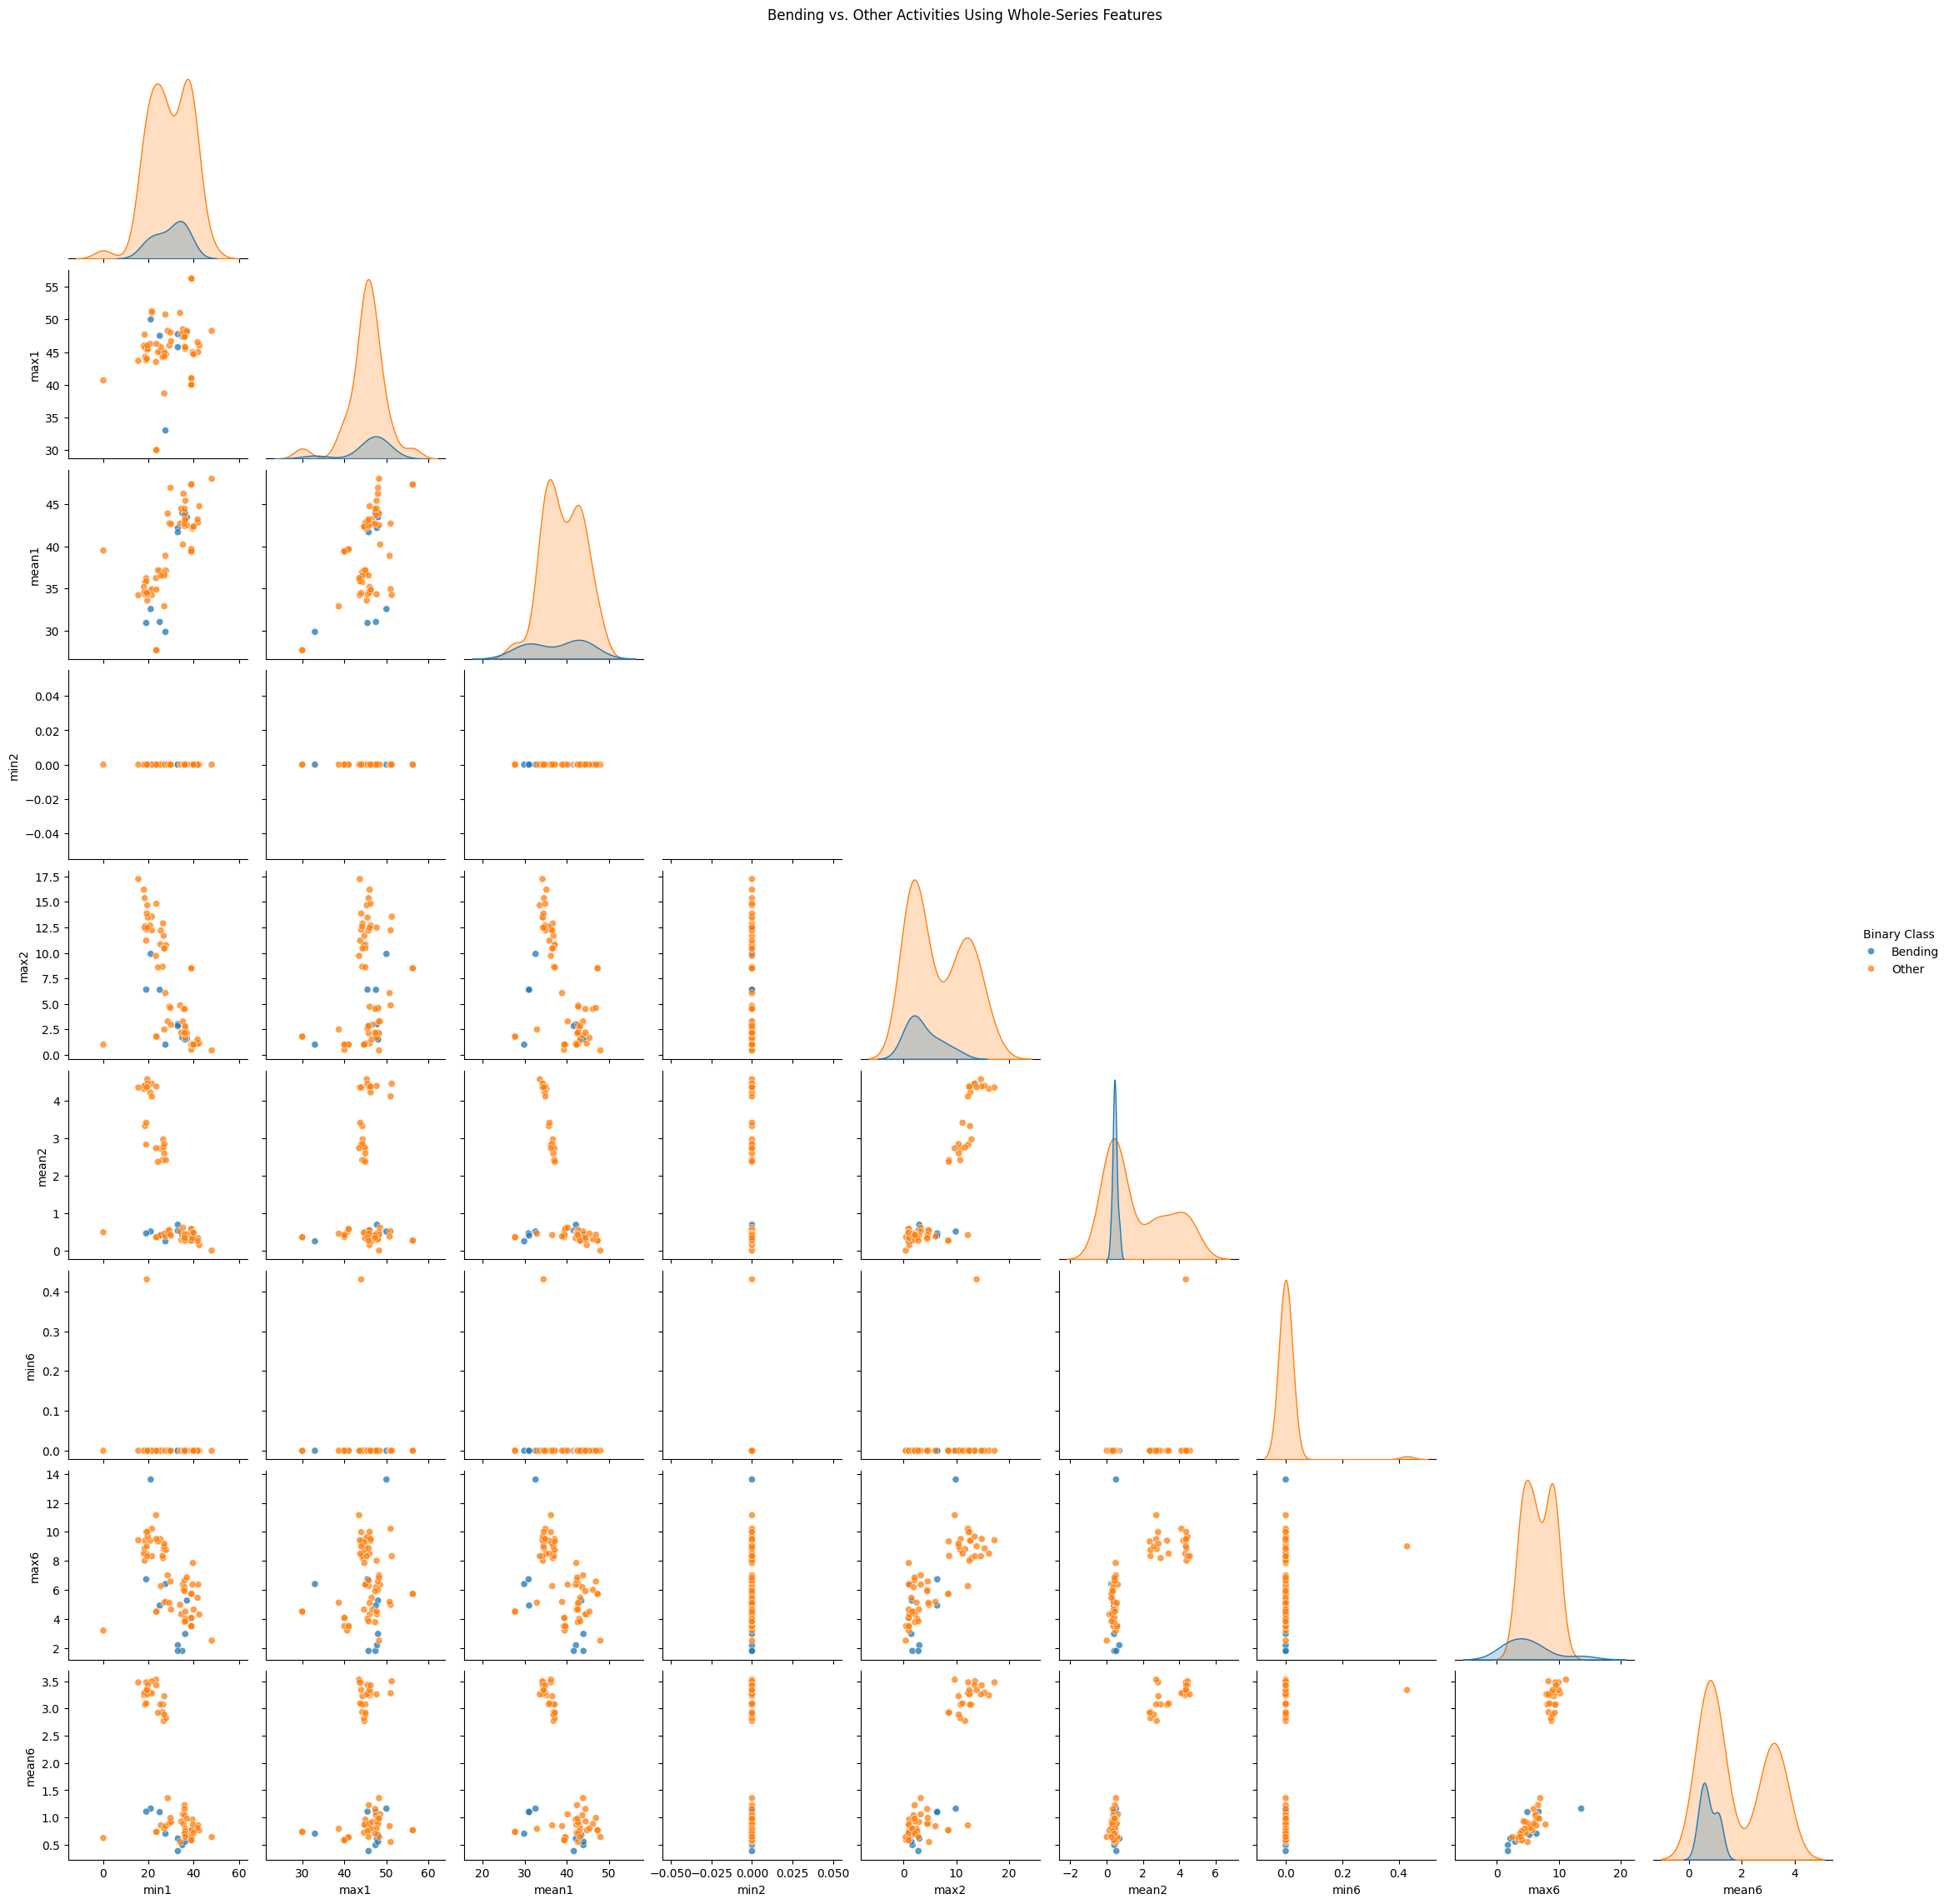

In [121]:
scatterplot = sns.pairplot(
    scatterplot_data,
    vars=scatterplot_features,
    hue="Binary Class",
    corner=True,
    plot_kws={
        "alpha": 0.75,
        "s": 35,
    },
)

scatterplot.fig.suptitle(
    "Bending vs. Other Activities Using Whole-Series Features",
    y=1.02,
)

plt.show()

**Answer:** The scatter-plot matrix compares the nine bending training
instances with the 60 non-bending training instances. The minimum values
of time series 2 and 6 provide very little separation because they are
zero for nearly all instances. The maximum and mean values of time series
2 and 6 show more useful separation because the bending observations
generally have lower values, although they overlap with some of the
non-bending observations. The minimum, maximum, and mean of time series 1
also show substantial overlap between the two classes. Therefore, no
single feature perfectly distinguishes bending from the other activities.
The usefulness of combinations of these features will be evaluated more
formally using logistic regression and cross-validation.

#### 2(a)(ii) - Scatter Plots After Splitting Each Time Series

In [122]:
two_part_feature_records = []
two_part_instance_records = []

training_instances = ordered_instances.loc[
    ordered_instances["Split"].eq("Train")
]

for instance_number, row in training_instances.iterrows():
    instance_data = load_instance(row["Path"])
    instance_features = {}

    for series_number, column in enumerate(
        time_series_columns,
        start=1,
    ):
        segments = np.array_split(
            instance_data[column].to_numpy(),
            2,
        )

        for part_number, segment in enumerate(
            segments,
            start=1,
        ):
            feature_suffix = (
                f"{series_number}_part{part_number}"
            )

            instance_features[
                f"min{feature_suffix}"
            ] = segment.min()

            instance_features[
                f"max{feature_suffix}"
            ] = segment.max()

            instance_features[
                f"mean{feature_suffix}"
            ] = segment.mean()

    two_part_feature_records.append(instance_features)

    two_part_instance_records.append({
        "Instance": instance_number + 1,
        "Activity": row["Activity"],
        "Dataset": row["Dataset"],
        "Split": row["Split"],
        "Binary Class": (
            "Bending"
            if row["Activity"] in {"bending1", "bending2"}
            else "Other"
        ),
    })

two_part_features = pd.DataFrame(
    two_part_feature_records,
)

two_part_information = pd.DataFrame(
    two_part_instance_records,
)

print("Feature shape:", two_part_features.shape)
print(
    "Missing feature values:",
    two_part_features.isna().sum().sum(),
)

two_part_information["Binary Class"].value_counts()

Feature shape: (69, 36)
Missing feature values: 0


Binary Class
Other      60
Bending     9
Name: count, dtype: int64

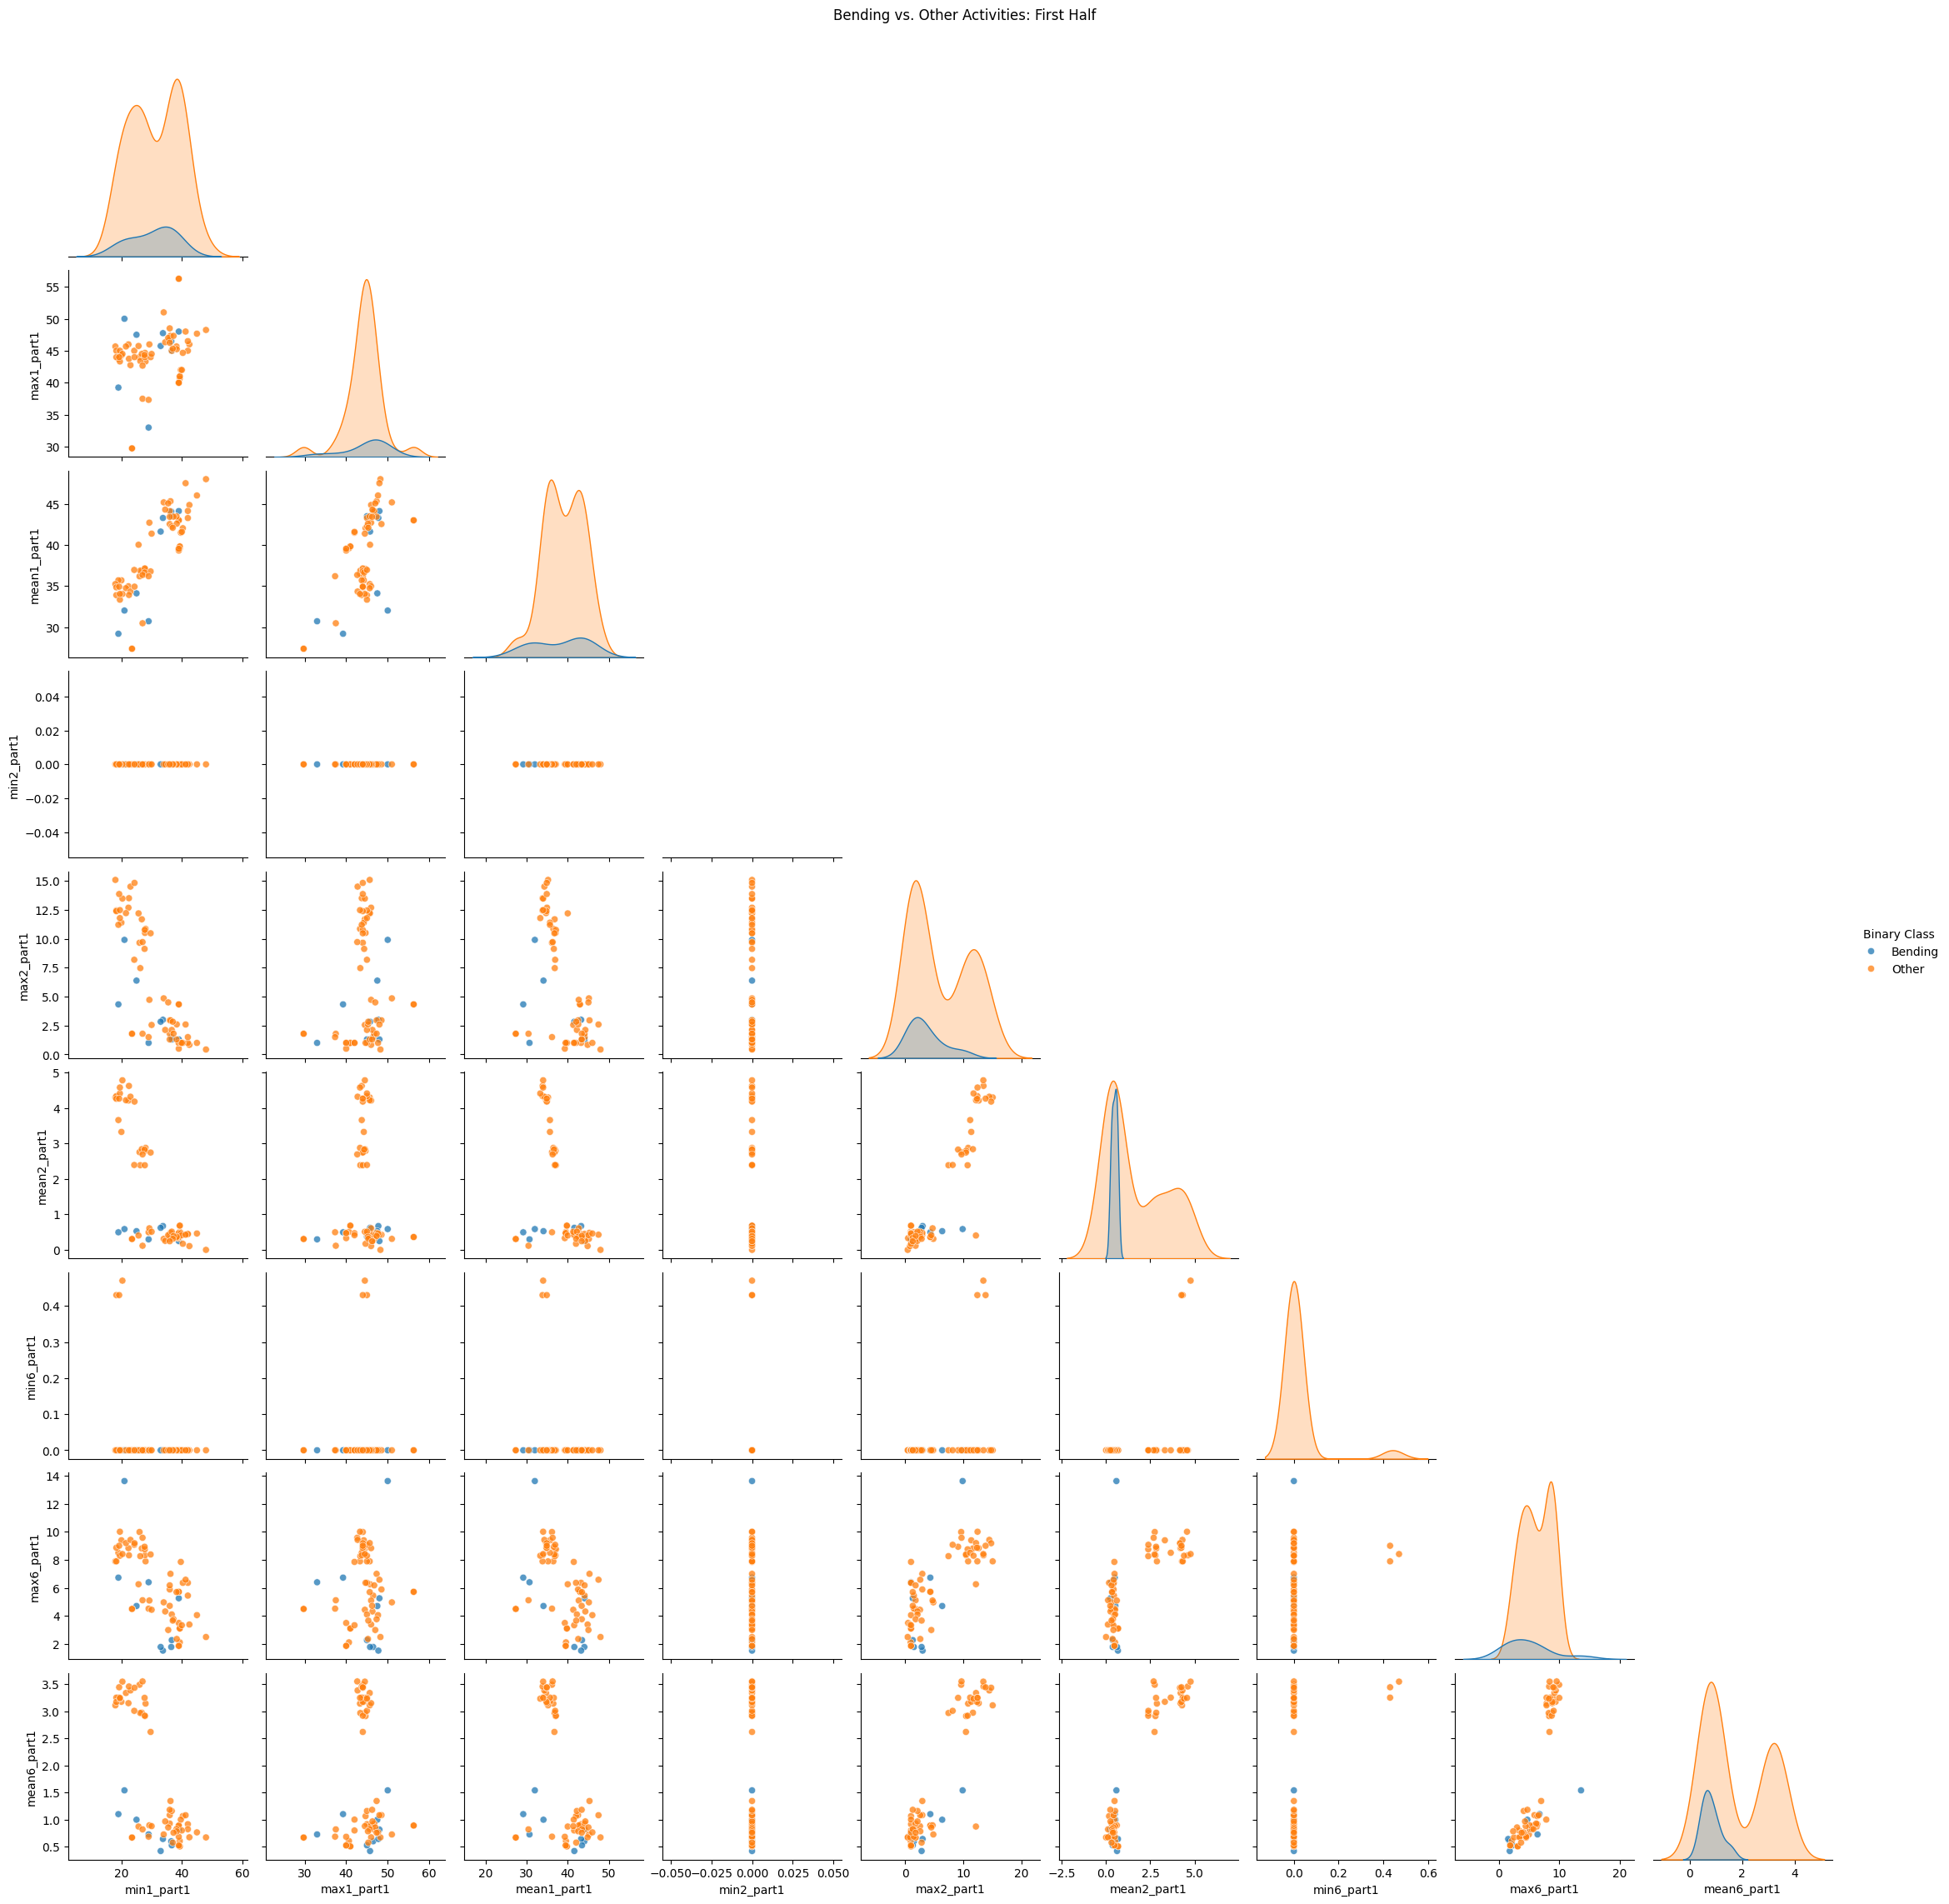

In [123]:
part_1_features = [
    "min1_part1",
    "max1_part1",
    "mean1_part1",
    "min2_part1",
    "max2_part1",
    "mean2_part1",
    "min6_part1",
    "max6_part1",
    "mean6_part1",
]

part_1_plot_data = two_part_features[
    part_1_features
].copy()

part_1_plot_data["Binary Class"] = (
    two_part_information["Binary Class"].to_numpy()
)

part_1_scatterplot = sns.pairplot(
    part_1_plot_data,
    vars=part_1_features,
    hue="Binary Class",
    corner=True,
    plot_kws={
        "alpha": 0.75,
        "s": 35,
    },
)

part_1_scatterplot.fig.suptitle(
    "Bending vs. Other Activities: First Half",
    y=1.02,
)

plt.show()

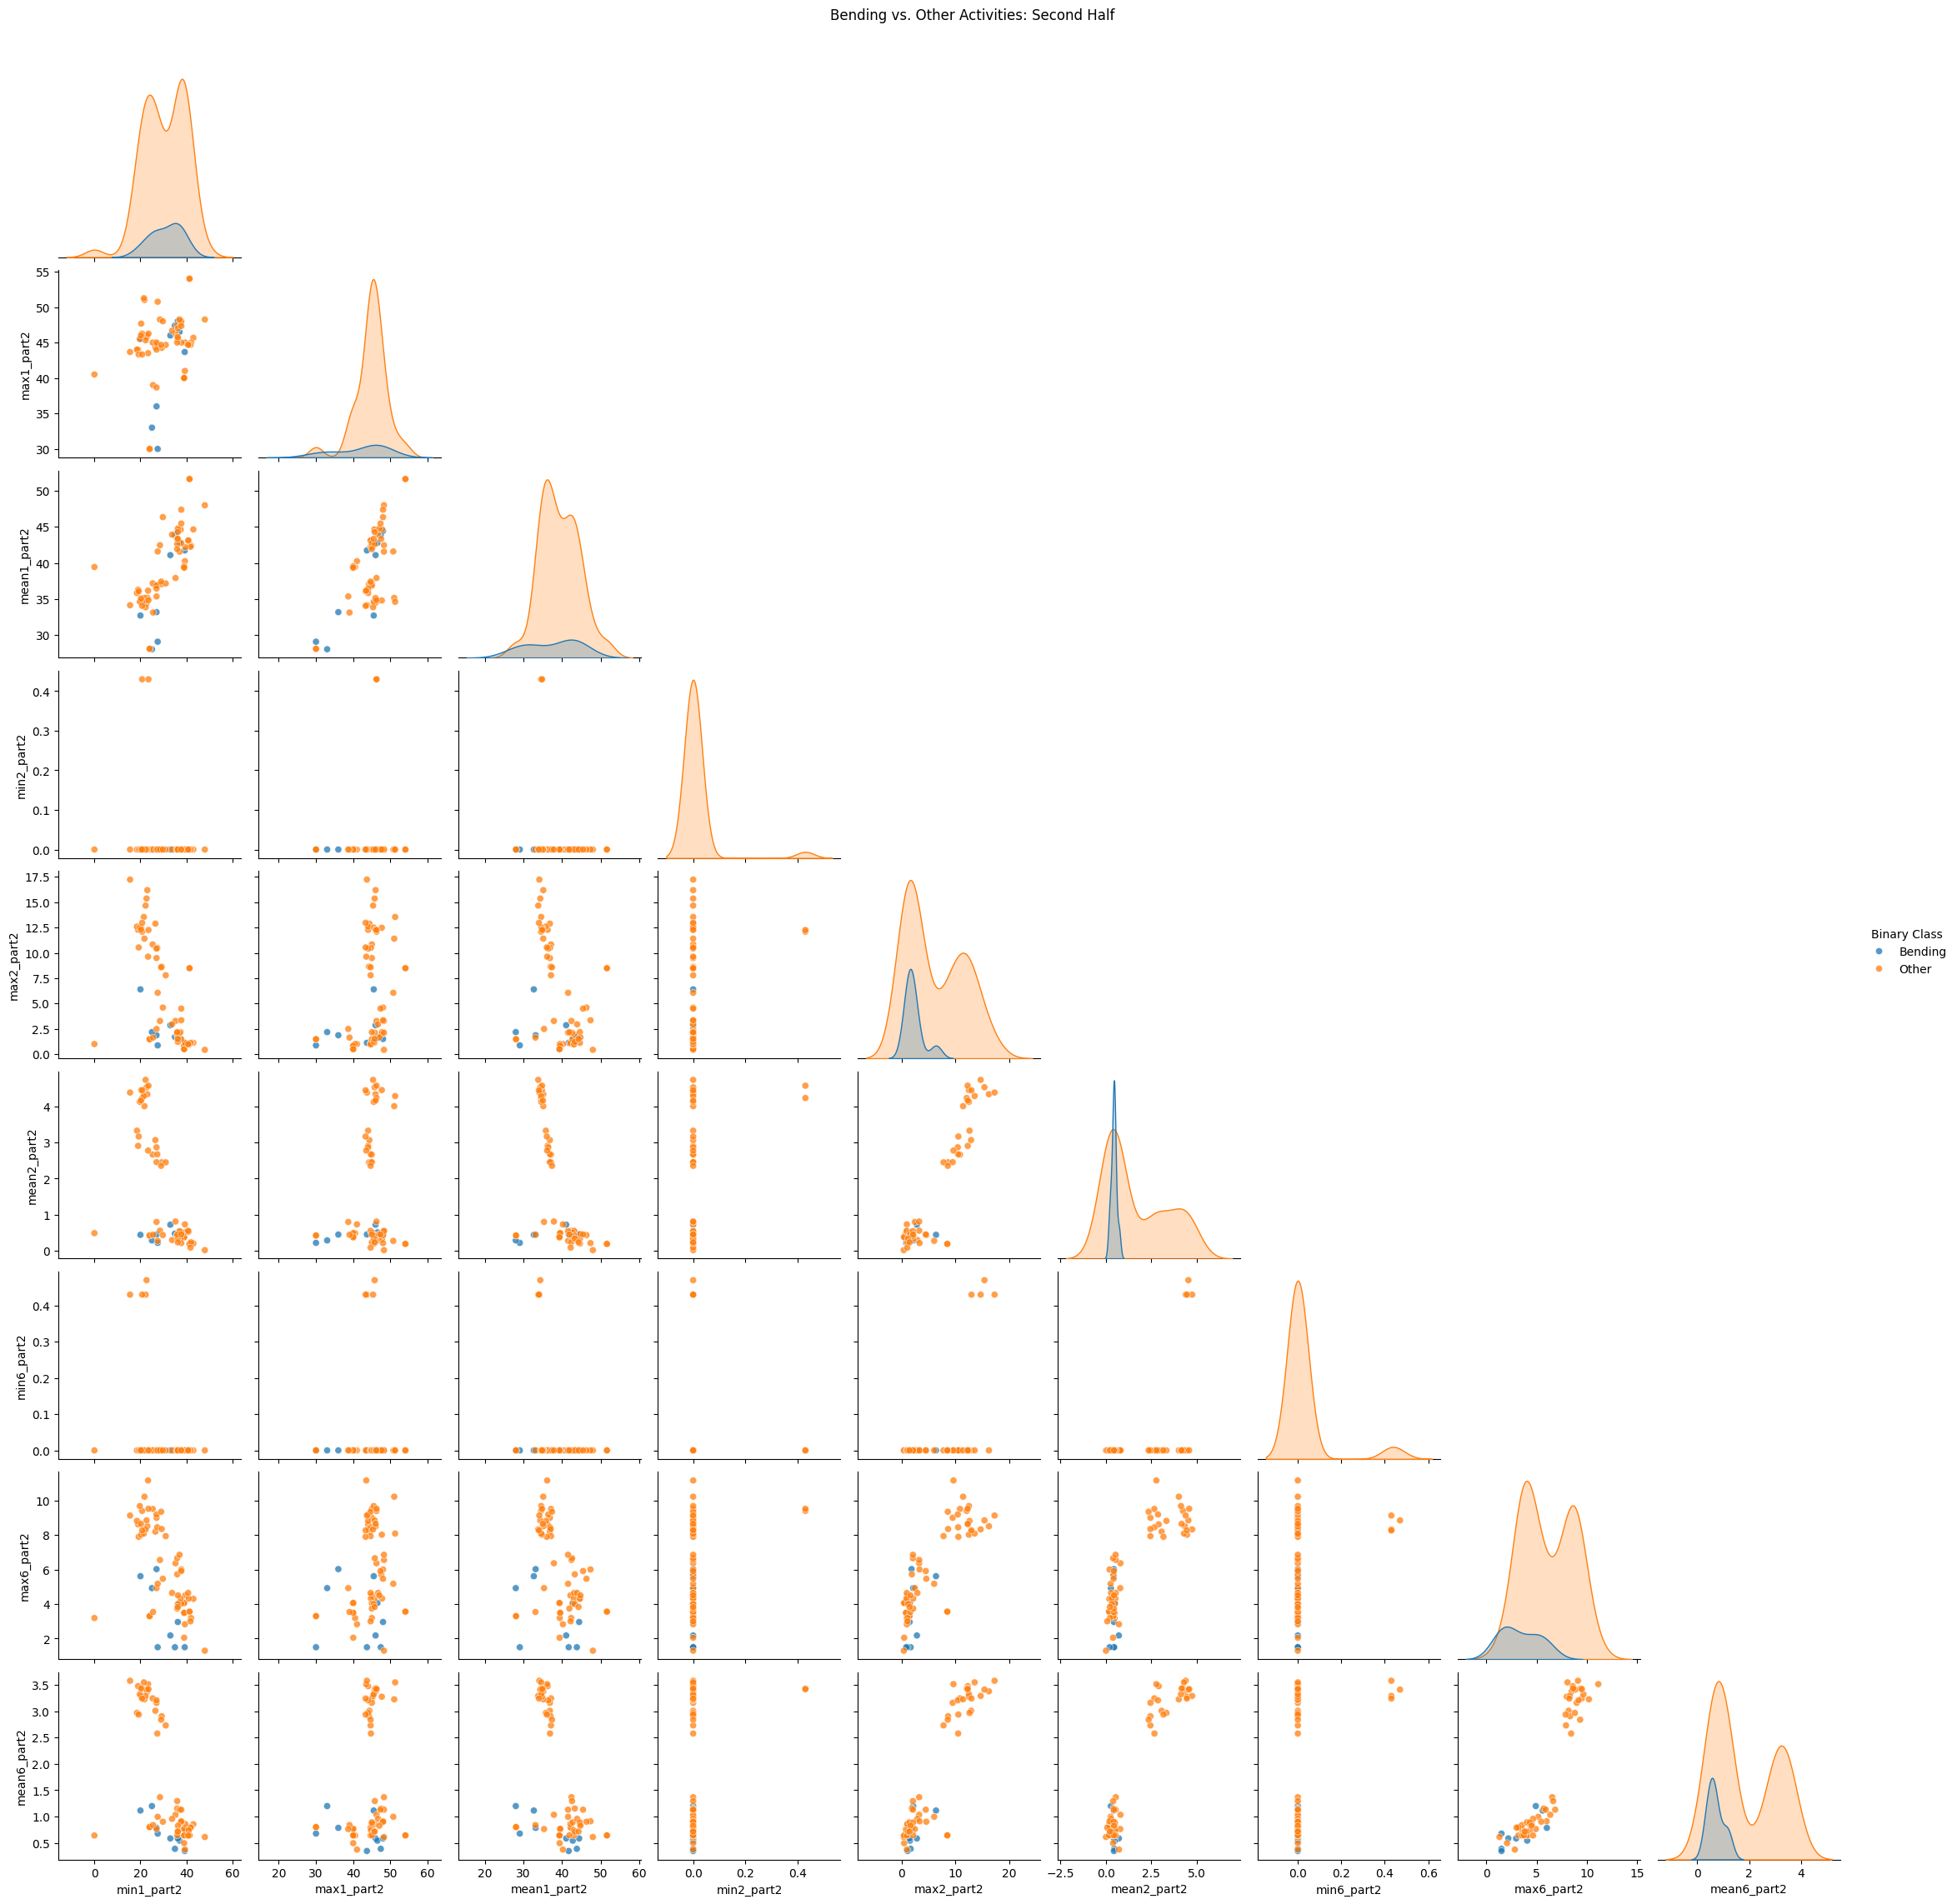

In [124]:
part_2_features = [
    "min1_part2",
    "max1_part2",
    "mean1_part2",
    "min2_part2",
    "max2_part2",
    "mean2_part2",
    "min6_part2",
    "max6_part2",
    "mean6_part2",
]

part_2_plot_data = two_part_features[
    part_2_features
].copy()

part_2_plot_data["Binary Class"] = (
    two_part_information["Binary Class"].to_numpy()
)

part_2_scatterplot = sns.pairplot(
    part_2_plot_data,
    vars=part_2_features,
    hue="Binary Class",
    corner=True,
    plot_kws={
        "alpha": 0.75,
        "s": 35,
    },
)

part_2_scatterplot.fig.suptitle(
    "Bending vs. Other Activities: Second Half",
    y=1.02,
)

plt.show()

**Answer:** Dividing each time series into two halves does not produce a considerable improvement in the visual separation between bending and the other activities. The first-half and second-half plots show patterns similar to those obtained using each complete time series.

The minimum values of time series 2 and 6 remain zero for nearly all training instances, so those features continue to provide little discriminating information. The maximum and mean values of time series 2 and 6 show some separation because the bending observations tend to have lower values. However, several non-bending observations occupy the same region. The features from time series 1 also continue to show substantial overlap.

Splitting the series preserves some information about differences between the first and second halves, but it does not make the two classes clearly separable in these scatter plots. Cross-validation is needed to determine whether the additional segmented features improve classification performance.

#### 2(a)(iii) - Selecting the Number of Segments and Features

In [125]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [126]:
def extract_segmented_features(dataset_path, number_of_segments):
    instance_data = load_instance(dataset_path)
    instance_features = {}

    for series_number, column in enumerate(
        time_series_columns,
        start=1,
    ):
        segments = np.array_split(
            instance_data[column].to_numpy(),
            number_of_segments,
        )

        for segment_number, segment in enumerate(
            segments,
            start=1,
        ):
            feature_suffix = (
                f"series{series_number}_"
                f"segment{segment_number}"
            )

            instance_features[
                f"min_{feature_suffix}"
            ] = segment.min()

            instance_features[
                f"max_{feature_suffix}"
            ] = segment.max()

            instance_features[
                f"mean_{feature_suffix}"
            ] = segment.mean()

            instance_features[
                f"median_{feature_suffix}"
            ] = np.median(segment)

            instance_features[
                f"std_{feature_suffix}"
            ] = segment.std(ddof=1)

            instance_features[
                f"1st_quart_{feature_suffix}"
            ] = np.quantile(segment, 0.25)

            instance_features[
                f"3rd_quart_{feature_suffix}"
            ] = np.quantile(segment, 0.75)

    return instance_features

In [127]:
def build_segmented_dataset(
    manifest,
    number_of_segments,
    split,
):
    selected_instances = manifest.loc[
        manifest["Split"].eq(split)
    ].sort_values(
        ["Activity", "Dataset"]
    )

    feature_records = []
    target_values = []

    for _, row in selected_instances.iterrows():
        instance_features = extract_segmented_features(
            row["Path"],
            number_of_segments,
        )

        feature_records.append(instance_features)

        target_values.append(
            int(
                row["Activity"]
                in {"bending1", "bending2"}
            )
        )

    feature_matrix = pd.DataFrame(feature_records)
    target = pd.Series(
        target_values,
        name="Bending",
    )

    return feature_matrix, target

In [128]:
for number_of_segments in [1, 2, 20]:
    example_features, example_target = (
        build_segmented_dataset(
            ordered_instances,
            number_of_segments,
            "Train",
        )
    )

    print(
        f"l={number_of_segments}:",
        example_features.shape,
    )

l=1: (69, 42)
l=2: (69, 84)
l=20: (69, 840)


In [129]:
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

In [130]:
rfe_estimator = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=5000,
)

model_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "rfe",
        RFE(
            estimator=rfe_estimator,
            step=0.1,
        ),
    ),
    (
        "logistic_regression",
        LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=5000,
        ),
    ),
])

In [131]:
cv_result_records = []
searches_by_segment_count = {}

for number_of_segments in range(1, 21):
    segmented_features, binary_target = (
        build_segmented_dataset(
            ordered_instances,
            number_of_segments,
            "Train",
        )
    )

    candidate_feature_counts = list(range(1, 21))

    parameter_grid = {
        "rfe__n_features_to_select": (
            candidate_feature_counts
        )
    }

    grid_search = GridSearchCV(
        estimator=model_pipeline,
        param_grid=parameter_grid,
        scoring="accuracy",
        cv=stratified_cv,
        n_jobs=-1,
        error_score="raise",
    )

    grid_search.fit(
        segmented_features,
        binary_target,
    )

    searches_by_segment_count[
        number_of_segments
    ] = grid_search

    for feature_count, mean_score, score_std in zip(
        grid_search.cv_results_[
            "param_rfe__n_features_to_select"
        ],
        grid_search.cv_results_["mean_test_score"],
        grid_search.cv_results_["std_test_score"],
    ):
        cv_result_records.append({
            "Segments": number_of_segments,
            "Selected Features": int(feature_count),
            "Mean CV Accuracy": mean_score,
            "CV Accuracy SD": score_std,
        })

    print(
        f"l={number_of_segments:2d}, "
        f"candidate features="
        f"{segmented_features.shape[1]:3d}, "
        f"best p="
        f"{grid_search.best_params_['rfe__n_features_to_select']:2d}, "
        f"accuracy={grid_search.best_score_:.4f}"
    )

l= 1, candidate features= 42, best p= 7, accuracy=0.9857
l= 2, candidate features= 84, best p=11, accuracy=0.9714
l= 3, candidate features=126, best p= 1, accuracy=0.9857
l= 4, candidate features=168, best p=10, accuracy=0.9714
l= 5, candidate features=210, best p= 7, accuracy=0.9275
l= 6, candidate features=252, best p=12, accuracy=1.0000
l= 7, candidate features=294, best p=11, accuracy=0.9429
l= 8, candidate features=336, best p=11, accuracy=0.9571
l= 9, candidate features=378, best p= 5, accuracy=0.9571
l=10, candidate features=420, best p=11, accuracy=0.9714
l=11, candidate features=462, best p=20, accuracy=0.9286
l=12, candidate features=504, best p=13, accuracy=0.9714
l=13, candidate features=546, best p=14, accuracy=0.9571
l=14, candidate features=588, best p=18, accuracy=0.9571
l=15, candidate features=630, best p=16, accuracy=0.9429
l=16, candidate features=672, best p=13, accuracy=0.9714
l=17, candidate features=714, best p=13, accuracy=0.9571
l=18, candidate features=756, b

In [132]:
cv_results = pd.DataFrame(cv_result_records)

ranked_cv_results = cv_results.sort_values(
    by=[
        "Mean CV Accuracy",
        "Selected Features",
        "Segments",
    ],
    ascending=[
        False,
        True,
        True,
    ],
).reset_index(drop=True)

ranked_cv_results.head(20)

,Segments,Selected Features,Mean CV Accuracy,CV Accuracy SD
0,6,12,1.000000,0.000000
1,6,13,1.000000,0.000000
2,3,1,0.985714,0.028571
3,1,7,0.985714,0.028571
4,1,8,0.985714,0.028571
5,1,9,0.985714,0.028571
6,6,9,0.985714,0.028571
7,6,10,0.985714,0.028571
8,1,11,0.985714,0.028571
9,6,11,0.985714,0.028571


In [133]:
best_result = ranked_cv_results.iloc[0]

best_number_of_segments = int(
    best_result["Segments"]
)

best_number_of_features = int(
    best_result["Selected Features"]
)

best_cv_accuracy = float(
    best_result["Mean CV Accuracy"]
)

print(
    "Best number of segments:",
    best_number_of_segments,
)

print(
    "Best number of selected features:",
    best_number_of_features,
)

print(
    "Best mean CV accuracy:",
    f"{best_cv_accuracy:.4f}",
)

Best number of segments: 6
Best number of selected features: 12
Best mean CV accuracy: 1.0000


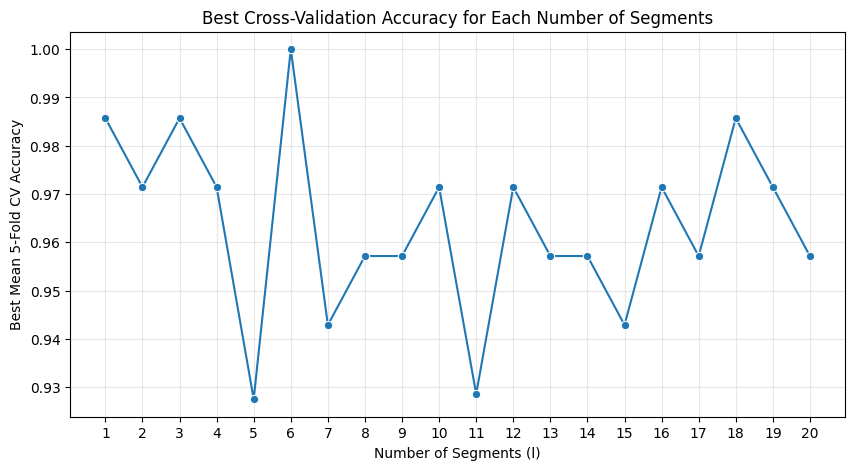

In [134]:
best_result_by_segment_count = (
    cv_results.sort_values(
        by=[
            "Segments",
            "Mean CV Accuracy",
            "Selected Features",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .groupby("Segments", as_index=False)
    .first()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=best_result_by_segment_count,
    x="Segments",
    y="Mean CV Accuracy",
    marker="o",
)

plt.xticks(range(1, 21))
plt.xlabel("Number of Segments (l)")
plt.ylabel("Best Mean 5-Fold CV Accuracy")
plt.title(
    "Best Cross-Validation Accuracy for Each Number of Segments"
)
plt.grid(alpha=0.3)
plt.show()

In [135]:
best_training_features, best_training_target = (
    build_segmented_dataset(
        ordered_instances,
        best_number_of_segments,
        "Train",
    )
)

final_rfe_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "rfe",
        RFE(
            estimator=LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=5000,
            ),
            n_features_to_select=(
                best_number_of_features
            ),
            step=0.1,
        ),
    ),
    (
        "logistic_regression",
        LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=5000,
        ),
    ),
])

final_rfe_pipeline.fit(
    best_training_features,
    best_training_target,
)

,steps,"[('scaler', ...), ('rfe', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,estimator,LogisticRegre... penalty=None)
,n_features_to_select,12
,step,0.1
,verbose,0


In [136]:
selected_feature_mask = (
    final_rfe_pipeline
    .named_steps["rfe"]
    .support_
)

selected_feature_names = (
    best_training_features.columns[
        selected_feature_mask
    ].tolist()
)

print(
    "Number of selected features:",
    len(selected_feature_names),
)

print("\nSelected features:")

for feature_name in selected_feature_names:
    print(feature_name)

Number of selected features: 12

Selected features:
median_series1_segment4
max_series2_segment2
std_series3_segment2
3rd_quart_series3_segment6
1st_quart_series4_segment5
max_series5_segment1
mean_series5_segment1
3rd_quart_series5_segment1
min_series5_segment2
max_series5_segment2
max_series5_segment6
max_series6_segment6


**Model-selection result:** Stratified five-fold cross-validation selected \(l=6\) segments and \(p=12\) features. Each original instance therefore produced \(6\times6\times7=252\) candidate features before recursive feature elimination. RFE retained 12 of these features.

The selected pair achieved a mean five-fold cross-validation accuracy of 1.0000. This value should be interpreted cautiously because the dataset contains only 69 training instances and only 9 belong to the bending class. The result will therefore be compared with performance on the untouched test set.

**Correct and incorrect cross-validation procedures:** The correct approach is to fit all data-dependent transformations using only the training portion of each cross-validation fold. For every candidate pair \((l,p)\), the scaler and RFE selector are fitted on the fold's training observations. Those fitted transformations are then applied to the validation observations before evaluating logistic regression. A pipeline was used to enforce this procedure.

The wrong approach would be to standardize all 69 training observations or select features using RFE before beginning cross-validation. In that case, information from each validation fold would influence the scaling parameters or selected features. This data leakage would make the cross-validation score overly optimistic.

Extracting summary statistics independently from each instance before cross-validation is acceptable because that calculation does not estimate parameters across instances. However, scaling, feature selection, and model fitting must occur inside each fold. The test set must not be used to select either \(l\) or \(p\).

Stratified cross-validation was used because only 9 of the 69 training instances are bending activities. Stratification preserves approximately the same class proportions in each fold and ensures that both classes are represented.

#### 2(a)(iv) - Training Confusion Matrix, ROC, AUC, and Model Parameters

In [137]:
import warnings

import statsmodels.api as sm

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)

from statsmodels.tools.sm_exceptions import (
    PerfectSeparationWarning,
)

In [138]:
training_predictions = final_rfe_pipeline.predict(
    best_training_features
)

training_probabilities = (
    final_rfe_pipeline.predict_proba(
        best_training_features
    )[:, 1]
)

training_accuracy = accuracy_score(
    best_training_target,
    training_predictions,
)

training_auc = roc_auc_score(
    best_training_target,
    training_probabilities,
)

print(
    "Training accuracy:",
    f"{training_accuracy:.4f}",
)

print(
    "Training AUC:",
    f"{training_auc:.4f}",
)

Training accuracy: 1.0000
Training AUC: 1.0000


In [139]:
training_confusion_matrix = confusion_matrix(
    best_training_target,
    training_predictions,
    labels=[0, 1],
)

training_confusion_matrix

array([[60,  0],
       [ 0,  9]])

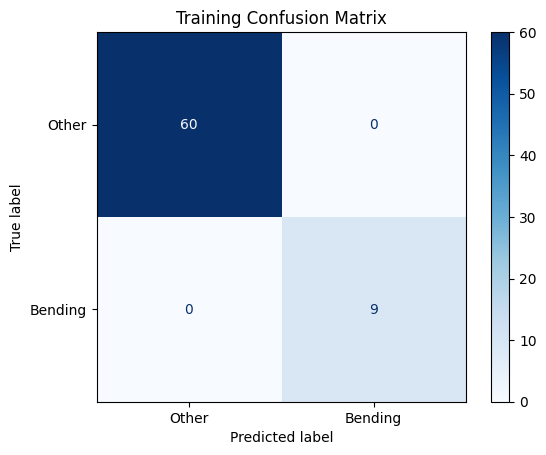

In [140]:
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=training_confusion_matrix,
    display_labels=["Other", "Bending"],
)

confusion_display.plot(
    cmap="Blues",
    values_format="d",
)

plt.title("Training Confusion Matrix")
plt.show()

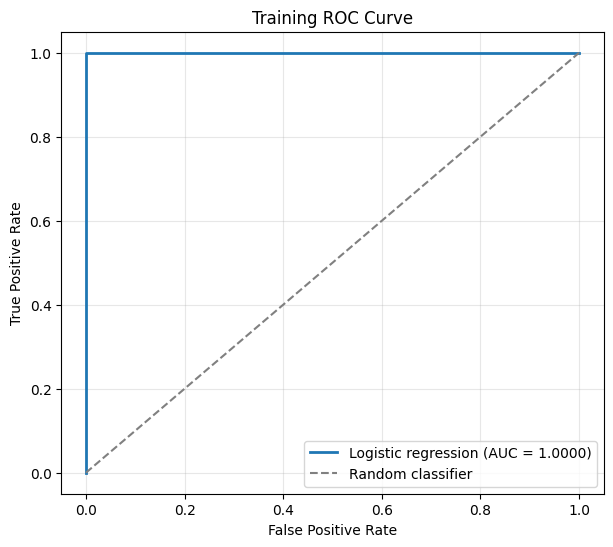

In [141]:
false_positive_rate, true_positive_rate, thresholds = (
    roc_curve(
        best_training_target,
        training_probabilities,
    )
)

plt.figure(figsize=(7, 6))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    linewidth=2,
    label=f"Logistic regression (AUC = {training_auc:.4f})",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [142]:
fitted_classifier = (
    final_rfe_pipeline
    .named_steps["logistic_regression"]
)

classifier_parameters = pd.DataFrame({
    "Parameter": [
        "Intercept",
        *selected_feature_names,
    ],
    "Coefficient": np.concatenate([
        fitted_classifier.intercept_,
        fitted_classifier.coef_.ravel(),
    ]),
})

classifier_parameters

,Parameter,Coefficient
0,Intercept,-10.080637
1,median_series1_segment4,-3.307354
2,max_series2_segment2,-1.277056
3,std_series3_segment2,0.641367
4,3rd_quart_series3_segment6,-1.685943
5,1st_quart_series4_segment5,-1.504697
6,max_series5_segment1,1.786775
7,mean_series5_segment1,2.513198
8,3rd_quart_series5_segment1,1.738924
9,min_series5_segment2,2.615425


In [143]:
fitted_scaler = (
    final_rfe_pipeline
    .named_steps["scaler"]
)

fitted_rfe = (
    final_rfe_pipeline
    .named_steps["rfe"]
)

standardized_training_features = (
    fitted_scaler.transform(
        best_training_features
    )
)

selected_standardized_features = (
    fitted_rfe.transform(
        standardized_training_features
    )
)

selected_training_dataframe = pd.DataFrame(
    selected_standardized_features,
    columns=selected_feature_names,
)

statsmodels_design_matrix = sm.add_constant(
    selected_training_dataframe,
    has_constant="add",
)

with warnings.catch_warnings():
    warnings.simplefilter(
        "once",
        PerfectSeparationWarning,
    )

    inference_model = sm.Logit(
        best_training_target.to_numpy(),
        statsmodels_design_matrix,
    )

    inference_result = inference_model.fit(
        disp=False,
        maxiter=100,
    )

print(
    "Statsmodels converged:",
    inference_result.mle_retvals["converged"],
)

inference_result.summary()

Statsmodels converged: False


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       56
Method:                           MLE   Df Model:                           12
Date:                Thu, 08 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        09:57:08   Log-Likelihood:            -2.2273e-10
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 3.446e-07
==============================================================================================
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const                        -31.0568   2.17e+05     -0.000      1.000   -4.26e+05    4.26e+05
median_series1_segment4      -10.8463   2.36e+05   -4.6e-05      1.000   -4.62e+05    4.62e+05
max_series2_segment2          -3.7702   6.31e+05  -5.97e-06      1.000   -1.24e+06    1.24e+06
std_series3_segment2           1.2891   4.67e+05   2.76e-06      1.000   -9.16e+05    9.16e+05
3rd_quart_series3_segment6    -6.8553   6.16e+05  -1.11e-05      1.000   -1.21e+06    1.21e+06
1st_quart_series4_segment5    -6.4842   1.54e+06  -4.21e-06      1.000   -3.02e+06    3.02e+06
max_series5_segment1           6.4402   8.65e+05   7.45e-06      1.000   -1.69e+06    1.69e+06
mean_series5_segment1          8.6123   6.55e+05   1.32e-05      1.000   -1.28e+06    1.28e+06
3rd_quart_series5_segment1     2.0838   1.63e+06   1.28e-06      1.000    -3.2e+06     3.2e+06
min_series5_segment2           8.1782   2.83e+05   2.89e-05      1.000   -5.55e+05    5.55e+05
max_series5_segment2          14.1359   2.71e+06   5.21e-06      1.000   -5.32e+06    5.32e+06
max_series5_segment6          -0.0356   1.22e+06  -2.93e-08      1.000   -2.39e+06    2.39e+06
max_series6_segment6          -1.6684   1.28e+06   -1.3e-06      1.000   -2.52e+06    2.52e+06
==============================================================================================

Complete Separation: The results show that there iscomplete separation or perfect prediction.
In this case the Maximum Likelihood Estimator does not exist and the parameters
are not identified.
"""

In [144]:
inference_results = pd.DataFrame({
    "Coefficient": inference_result.params,
    "Standard Error": inference_result.bse,
    "z-value": inference_result.tvalues,
    "p-value": inference_result.pvalues,
})

inference_results

,Coefficient,Standard Error,z-value,p-value
const,-31.056794,2.171786e+05,-1.430012e-04,0.999886
median_series1_segment4,-10.846260,2.357450e+05,-4.600843e-05,0.999963
max_series2_segment2,-3.770233,6.310318e+05,-5.974711e-06,0.999995
std_series3_segment2,1.289076,4.674441e+05,2.757711e-06,0.999998
3rd_quart_series3_segment6,-6.855312,6.155310e+05,-1.113723e-05,0.999991
1st_quart_series4_segment5,-6.484196,1.539107e+06,-4.212961e-06,0.999997
max_series5_segment1,6.440231,8.646425e+05,7.448432e-06,0.999994
mean_series5_segment1,8.612269,6.547615e+05,1.315329e-05,0.999990
3rd_quart_series5_segment1,2.083766,1.630679e+06,1.277851e-06,0.999999
min_series5_segment2,8.178183,2.832131e+05,2.887643e-05,0.999977


**Answer:** The training confusion matrix was

\[
\begin{bmatrix}
60 & 0\\
0 & 9
\end{bmatrix}.
\]

Therefore, the classifier correctly classified all 60 non-bending instances and all 9 bending instances in the training set. The training accuracy was 1.0000. The ROC curve reached the upper-left corner, and the training AUC was also 1.0000.

The fitted scikit-learn coefficients are reported above. Because the predictors were standardized before RFE and logistic regression, each coefficient represents the estimated change in the log odds of bending for a one-standard-deviation increase in the corresponding feature, holding the other selected features constant.

The p-values were also requested, so the selected standardized predictors were fitted using an unpenalized statsmodels logistic-regression model. However, statsmodels detected complete separation and did not converge to finite maximum-likelihood estimates. The resulting standard errors were extremely large and the reported Wald p-values were approximately 1.000. These p-values are not statistically reliable: under complete separation, the unpenalized maximum-likelihood coefficients are not finite or identifiable.

The perfect training confusion matrix and AUC should therefore be interpreted as evidence of strong separation rather than definitive evidence of perfect generalization. Performance on the untouched test set is evaluated separately.

#### 2(a)(v) - Evaluation on the Test Set

In [145]:
best_test_features, best_test_target = (
    build_segmented_dataset(
        ordered_instances,
        best_number_of_segments,
        "Test",
    )
)

print(
    "Test feature shape:",
    best_test_features.shape,
)

print(
    "Test class counts:"
)

print(
    best_test_target.value_counts()
    .sort_index()
)

Test feature shape: (19, 252)
Test class counts:
Bending
0    15
1     4
Name: count, dtype: int64


In [146]:
assert (
    best_test_features.columns.tolist()
    == best_training_features.columns.tolist()
)

assert (
    best_test_features.shape[1]
    == best_training_features.shape[1]
)

In [147]:
test_predictions = final_rfe_pipeline.predict(
    best_test_features
)

test_probabilities = (
    final_rfe_pipeline.predict_proba(
        best_test_features
    )[:, 1]
)

In [148]:
test_accuracy = accuracy_score(
    best_test_target,
    test_predictions,
)

print(
    "Cross-validation accuracy:",
    f"{best_cv_accuracy:.4f}",
)

print(
    "Test accuracy:",
    f"{test_accuracy:.4f}",
)

print(
    "Difference:",
    f"{best_cv_accuracy - test_accuracy:.4f}",
)

Cross-validation accuracy: 1.0000
Test accuracy: 0.9474
Difference: 0.0526


In [149]:
test_confusion_matrix = confusion_matrix(
    best_test_target,
    test_predictions,
    labels=[0, 1],
)

test_confusion_matrix

array([[15,  0],
       [ 1,  3]])

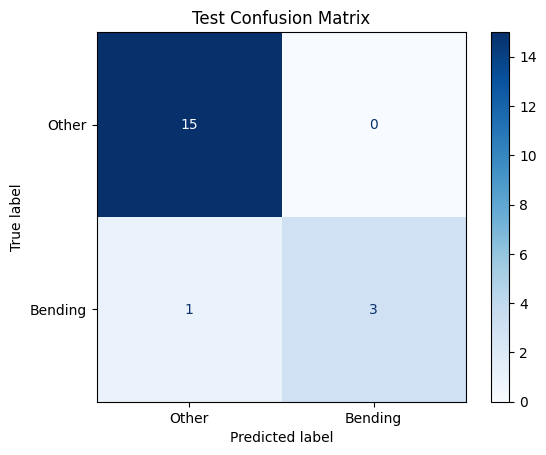

In [150]:
test_confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=test_confusion_matrix,
    display_labels=["Other", "Bending"],
)

test_confusion_display.plot(
    cmap="Blues",
    values_format="d",
)

plt.title("Test Confusion Matrix")
plt.show()

In [151]:
test_instance_information = (
    ordered_instances.loc[
        ordered_instances["Split"].eq("Test")
    ]
    .sort_values(
        ["Activity", "Dataset"]
    )
    .reset_index(drop=True)
)

test_prediction_results = pd.DataFrame({
    "Activity": (
        test_instance_information["Activity"]
    ),
    "Dataset": (
        test_instance_information["Dataset"]
    ),
    "Actual Class": best_test_target.map({
        0: "Other",
        1: "Bending",
    }),
    "Predicted Class": pd.Series(
        test_predictions
    ).map({
        0: "Other",
        1: "Bending",
    }),
    "Bending Probability": test_probabilities,
})

test_prediction_results

,Activity,Dataset,Actual Class,Predicted Class,Bending Probability
0,bending1,1,Bending,Bending,1.000000e+00
1,bending1,2,Bending,Bending,1.000000e+00
2,bending2,1,Bending,Bending,9.999883e-01
3,bending2,2,Bending,Other,3.518250e-01
4,cycling,1,Other,Other,7.798468e-05
5,cycling,2,Other,Other,1.778178e-04
6,cycling,3,Other,Other,1.593702e-04
7,lying,1,Other,Other,8.302403e-05
8,lying,2,Other,Other,6.139437e-11
9,lying,3,Other,Other,2.304807e-13


In [152]:
test_prediction_results.loc[
    test_prediction_results["Actual Class"]
    != test_prediction_results["Predicted Class"]
]

,Activity,Dataset,Actual Class,Predicted Class,Bending Probability
3,bending2,2,Bending,Other,0.351825


In [153]:
accuracy_comparison = pd.DataFrame({
    "Evaluation": [
        "Mean 5-Fold Cross-Validation",
        "Test Set",
    ],
    "Accuracy": [
        best_cv_accuracy,
        test_accuracy,
    ],
})

accuracy_comparison

,Evaluation,Accuracy
0,Mean 5-Fold Cross-Validation,1.000000
1,Test Set,0.947368


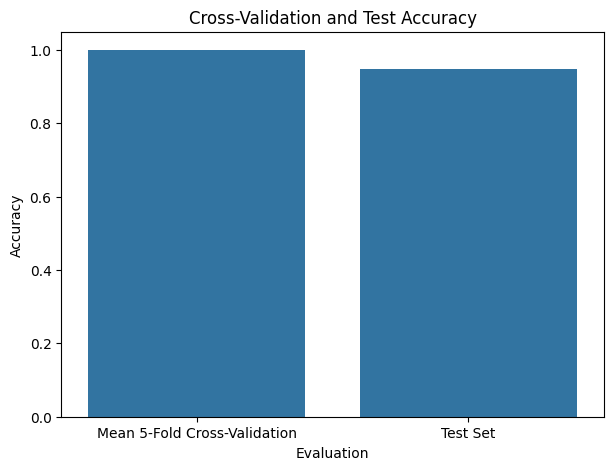

In [154]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=accuracy_comparison,
    x="Evaluation",
    y="Accuracy",
)

plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(
    "Cross-Validation and Test Accuracy"
)

plt.show()

**Answer:** The test time series were divided into the same \(l=6\) segments selected using the training data. This produced 252 candidate test features per instance. The scaler, RFE selector, and logistic regression model fitted using the training data were then applied to the test features without refitting any part of the pipeline.

The classifier correctly classified 18 of the 19 test instances, giving a test accuracy of

\[
\frac{18}{19}=0.9474.
\]

The test confusion matrix was

\[
\begin{bmatrix}
15 & 0\\
1 & 3
\end{bmatrix}.
\]

All 15 non-bending instances were classified correctly. Three of the four bending instances were classified correctly, while one bending instance was incorrectly classified as non-bending.

The mean five-fold cross-validation accuracy was 1.0000, while the test accuracy was 0.9474. Thus, the test accuracy was 0.0526, or 5.26 percentage points, lower than the cross-validation accuracy. Because the test set contains only 19 instances, one incorrect prediction changes the test accuracy by \(1/19=0.0526\). The result therefore remains close to the cross-validation estimate, although the perfect cross-validation score was slightly optimistic.

#### 2(a)(vi) - Separation and Parameter Instability

**Answer:** Yes, the classes appear to be sufficiently well separated in the training data to cause instability in the unpenalized logistic regression parameters. The classifier achieved a perfect training confusion matrix,

\[
\begin{bmatrix}
60 & 0\\
0 & 9
\end{bmatrix},
\]

and a training AUC of 1.0000. In addition, statsmodels issued a complete separation warning and failed to converge to finite maximum-likelihood estimates.

Under complete separation, a combination of the predictors perfectly separates the bending and non-bending training observations. Increasing the magnitudes of the logistic regression coefficients then continues to improve the likelihood, so no unique finite maximum-likelihood estimate exists. This explains the extremely large standard errors, unstable coefficient estimates, and unreliable p-values obtained from statsmodels.

Scikit-learn returned finite coefficients because its numerical optimization procedure stopped at finite values, but these should not be interpreted as stable maximum-likelihood estimates. The lower test accuracy of 0.9474 also shows that perfect separation of the training data does not imply perfect classification of unseen observations.

#### 2(a)(vii) - Case-Control Sampling

In [155]:
class_balance_summary = pd.DataFrame({
    "Training": (
        best_training_target
        .value_counts()
        .sort_index()
    ),
    "Test": (
        best_test_target
        .value_counts()
        .sort_index()
    ),
})

class_balance_summary.index = [
    "Other",
    "Bending",
]

class_balance_summary

,Training,Test
Other,60,15
Bending,9,4


In [156]:
case_indices = best_training_target.loc[
    best_training_target.eq(1)
].index

control_indices = best_training_target.loc[
    best_training_target.eq(0)
].sample(
    n=len(case_indices),
    random_state=42,
).index

case_control_indices = pd.Index(
    np.concatenate([
        case_indices.to_numpy(),
        control_indices.to_numpy(),
    ])
)

case_control_features = (
    best_training_features.loc[
        case_control_indices,
        selected_feature_names,
    ]
)

case_control_target = (
    best_training_target.loc[
        case_control_indices
    ]
)

case_control_target.value_counts()

Bending
1    9
0    9
Name: count, dtype: int64

In [157]:
case_control_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "logistic_regression",
        LogisticRegression(
            penalty=None,
            solver="lbfgs",
            max_iter=5000,
        ),
    ),
])

case_control_pipeline.fit(
    case_control_features,
    case_control_target,
)

,steps,"[('scaler', ...), ('logistic_regression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,None
,dual,False
,tol,0.0001
,C,1.0


In [158]:
population_prevalence = (
    best_training_target.mean()
)

sampled_prevalence = (
    case_control_target.mean()
)

intercept_adjustment = (
    np.log(
        population_prevalence
        / (1 - population_prevalence)
    )
    - np.log(
        sampled_prevalence
        / (1 - sampled_prevalence)
    )
)

print(
    "Original training prevalence:",
    f"{population_prevalence:.4f}",
)

print(
    "Case-control sample prevalence:",
    f"{sampled_prevalence:.4f}",
)

print(
    "Intercept adjustment:",
    f"{intercept_adjustment:.4f}",
)

Original training prevalence: 0.1304
Case-control sample prevalence: 0.5000
Intercept adjustment: -1.8971


In [159]:
case_control_classifier = (
    case_control_pipeline
    .named_steps["logistic_regression"]
)

unadjusted_intercept = float(
    case_control_classifier.intercept_[0]
)

adjusted_intercept = (
    unadjusted_intercept
    + intercept_adjustment
)

case_control_classifier.intercept_[0] = (
    adjusted_intercept
)

print(
    "Unadjusted intercept:",
    f"{unadjusted_intercept:.6f}",
)

print(
    "Adjusted intercept:",
    f"{adjusted_intercept:.6f}",
)

Unadjusted intercept: 0.656654
Adjusted intercept: -1.240466


In [160]:
case_control_parameters = pd.DataFrame({
    "Parameter": [
        "Intercept",
        *selected_feature_names,
    ],
    "Adjusted Coefficient": np.concatenate([
        [adjusted_intercept],
        case_control_classifier.coef_.ravel(),
    ]),
})

case_control_parameters

,Parameter,Adjusted Coefficient
0,Intercept,-1.240466
1,median_series1_segment4,-3.073801
2,max_series2_segment2,-1.010545
3,std_series3_segment2,-0.776069
4,3rd_quart_series3_segment6,-0.545934
5,1st_quart_series4_segment5,-2.830966
6,max_series5_segment1,2.844408
7,mean_series5_segment1,2.494358
8,3rd_quart_series5_segment1,2.591740
9,min_series5_segment2,1.753285


In [161]:
case_control_test_features = (
    best_test_features[
        selected_feature_names
    ]
)

case_control_test_predictions = (
    case_control_pipeline.predict(
        case_control_test_features
    )
)

case_control_test_probabilities = (
    case_control_pipeline.predict_proba(
        case_control_test_features
    )[:, 1]
)

case_control_test_accuracy = accuracy_score(
    best_test_target,
    case_control_test_predictions,
)

case_control_test_auc = roc_auc_score(
    best_test_target,
    case_control_test_probabilities,
)

print(
    "Case-control test accuracy:",
    f"{case_control_test_accuracy:.4f}",
)

print(
    "Case-control test AUC:",
    f"{case_control_test_auc:.4f}",
)

Case-control test accuracy: 1.0000
Case-control test AUC: 1.0000


In [162]:
case_control_test_confusion_matrix = (
    confusion_matrix(
        best_test_target,
        case_control_test_predictions,
        labels=[0, 1],
    )
)

case_control_test_confusion_matrix

array([[15,  0],
       [ 0,  4]])

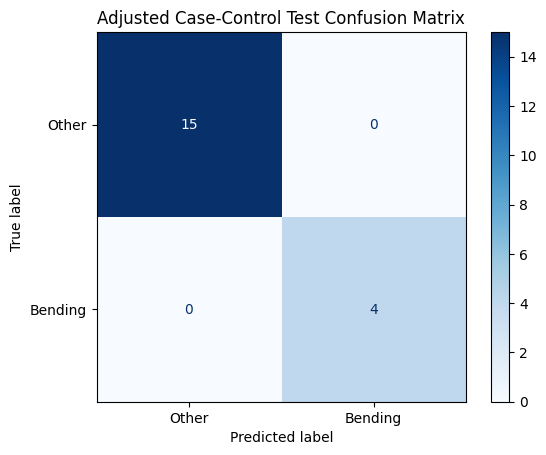

In [163]:
case_control_confusion_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=(
            case_control_test_confusion_matrix
        ),
        display_labels=[
            "Other",
            "Bending",
        ],
    )
)

case_control_confusion_display.plot(
    cmap="Blues",
    values_format="d",
)

plt.title(
    "Adjusted Case-Control Test Confusion Matrix"
)

plt.show()

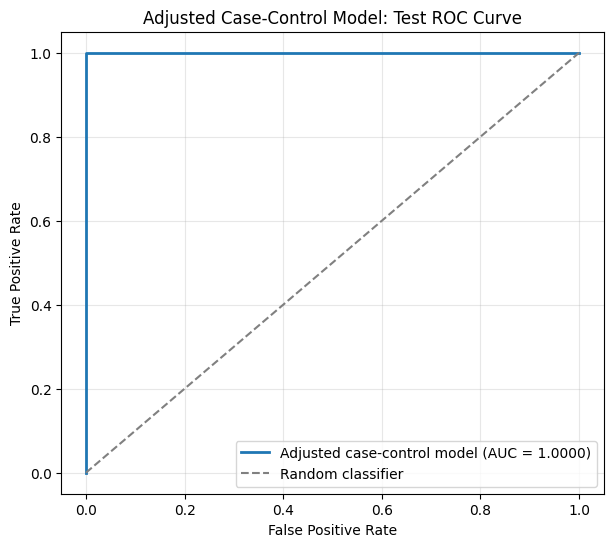

In [164]:
(
    case_control_false_positive_rate,
    case_control_true_positive_rate,
    case_control_thresholds,
) = roc_curve(
    best_test_target,
    case_control_test_probabilities,
)

plt.figure(figsize=(7, 6))

plt.plot(
    case_control_false_positive_rate,
    case_control_true_positive_rate,
    linewidth=2,
    label=(
        "Adjusted case-control model "
        f"(AUC = {case_control_test_auc:.4f})"
    ),
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "Adjusted Case-Control Model: Test ROC Curve"
)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

In [165]:
case_control_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Adjusted Case-Control Logistic Regression",
    ],
    "Test Accuracy": [
        test_accuracy,
        case_control_test_accuracy,
    ],
    "Test AUC": [
        roc_auc_score(
            best_test_target,
            test_probabilities,
        ),
        case_control_test_auc,
    ],
})

case_control_comparison

,Model,Test Accuracy,Test AUC
0,Original Logistic Regression,0.947368,1.0
1,Adjusted Case-Control Logistic Regression,1.000000,1.0


**Answer:** Yes, the binary classes are imbalanced. The original training set contains 60 non-bending instances and only 9 bending instances, so bending represents \(9/69=0.1304\), or approximately 13.04%, of the training observations. The test set similarly contains 15 non-bending and 4 bending instances.

A case-control training sample was constructed by retaining all 9 bending instances and randomly selecting 9 of the 60 non-bending instances. This produced a balanced sample with a bending prevalence of 0.5. Logistic regression was fitted using the 12 previously selected features.

Because case-control sampling changes the observed class prevalence, the intercept was corrected using

\[
\log\left(\frac{0.1304}{1-0.1304}\right)
-
\log\left(\frac{0.5}{1-0.5}\right)
=-1.8971.
\]

This correction was added to the sampled model's intercept, while the slope coefficients were left unchanged.

When evaluated on the untouched test set, the adjusted case-control model produced the confusion matrix

\[
\begin{bmatrix}
15 & 0\\
0 & 4
\end{bmatrix}.
\]

Thus, all 15 non-bending instances and all 4 bending instances were classified correctly. The test accuracy and AUC were both 1.0000. In comparison, the original logistic-regression model had a test accuracy of 0.9474 and an AUC of 1.0000.

The case-control result depends on the randomly sampled controls and the test set contains only 19 observations, so the apparent improvement should be interpreted cautiously.

### 2(b) - Binary Classification Using L1-Penalized Logistic Regression

#### 2(b)(i) - Selecting \(l\) and \(C\) Using Cross-Validation

L1-penalized logistic regression is used to perform classification and feature selection simultaneously. The number of segments \(l\) and the inverse regularization strength \(C\) are selected using stratified five-fold cross-validation. Smaller values of  (C\) correspond to stronger L1 regularization and therefore generally produce fewer nonzero coefficients.

In [190]:
l1_candidate_c_values = np.logspace(
    -4,
    4,
    25,
)

l1_model_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "logistic_regression",
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            max_iter=5000,
            random_state=42,
        ),
    ),
])

print(l1_model_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic_regression',
                 LogisticRegression(max_iter=5000, penalty='l1',
                                    random_state=42, solver='liblinear'))])


In [191]:
l1_result_records = []
l1_models_by_segment_count = {}

for number_of_segments in range(1, 21):
    l1_training_features, l1_training_target = (
        build_segmented_dataset(
            ordered_instances,
            number_of_segments,
            "Train",
        )
    )

    l1_grid_search = GridSearchCV(
        estimator=l1_model_pipeline,
        param_grid={
            "logistic_regression__C": (
                l1_candidate_c_values
            ),
        },
        scoring="accuracy",
        cv=stratified_cv,
        n_jobs=-1,
        error_score="raise",
    )

    l1_grid_search.fit(
        l1_training_features,
        l1_training_target,
    )

    mean_scores = (
        l1_grid_search
        .cv_results_["mean_test_score"]
    )

    best_mean_score = mean_scores.max()

    tied_indices = np.flatnonzero(
        np.isclose(
            mean_scores,
            best_mean_score,
        )
    )

    candidate_values = np.asarray(
        l1_grid_search.cv_results_[
            "param_logistic_regression__C"
        ],
        dtype=float,
    )

    # Among tied scores, prefer the stronger penalty.
    selected_index = tied_indices[
        np.argmin(
            candidate_values[tied_indices]
        )
    ]

    selected_c = float(
        candidate_values[selected_index]
    )

    selected_score_sd = float(
        l1_grid_search.cv_results_[
            "std_test_score"
        ][selected_index]
    )

    selected_l1_pipeline = Pipeline([
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "logistic_regression",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=selected_c,
                max_iter=5000,
                random_state=42,
            ),
        ),
    ])

    selected_l1_pipeline.fit(
        l1_training_features,
        l1_training_target,
    )

    number_of_nonzero_coefficients = int(
        np.count_nonzero(
            selected_l1_pipeline
            .named_steps["logistic_regression"]
            .coef_
        )
    )

    l1_result_records.append({
        "Segments": number_of_segments,
        "C": selected_c,
        "Approximate Lambda": 1 / selected_c,
        "Mean CV Accuracy": best_mean_score,
        "CV Accuracy SD": selected_score_sd,
        "Nonzero Coefficients": (
            number_of_nonzero_coefficients
        ),
    })

    l1_models_by_segment_count[
        number_of_segments
    ] = selected_l1_pipeline

    print(
        f"l={number_of_segments:2d}, "
        f"C={selected_c:.6f}, "
        f"accuracy={best_mean_score:.4f}, "
        f"nonzero="
        f"{number_of_nonzero_coefficients}"
    )

l= 1, C=10000.000000, accuracy=0.9714, nonzero=36
l= 2, C=1.000000, accuracy=0.9571, nonzero=8
l= 3, C=0.464159, accuracy=0.9714, nonzero=8
l= 4, C=0.464159, accuracy=0.9714, nonzero=8
l= 5, C=2.154435, accuracy=0.9418, nonzero=13
l= 6, C=2.154435, accuracy=0.9571, nonzero=14
l= 7, C=0.464159, accuracy=0.9275, nonzero=10
l= 8, C=10000.000000, accuracy=0.9571, nonzero=227
l= 9, C=10000.000000, accuracy=0.9286, nonzero=141
l=10, C=100.000000, accuracy=0.9714, nonzero=34
l=11, C=1.000000, accuracy=0.9714, nonzero=8
l=12, C=0.464159, accuracy=0.9857, nonzero=5
l=13, C=0.464159, accuracy=0.9714, nonzero=9
l=14, C=1.000000, accuracy=0.9714, nonzero=12
l=15, C=1000.000000, accuracy=0.9571, nonzero=90
l=16, C=21.544347, accuracy=0.9429, nonzero=25
l=17, C=46.415888, accuracy=0.9571, nonzero=36
l=18, C=0.464159, accuracy=0.9714, nonzero=7
l=19, C=1.000000, accuracy=0.9857, nonzero=10
l=20, C=21.544347, accuracy=0.9857, nonzero=25


In [192]:
l1_result_records = []
l1_models_by_segment_count = {}

for number_of_segments in range(1, 21):
    l1_training_features, l1_training_target = (
        build_segmented_dataset(
            ordered_instances,
            number_of_segments,
            "Train",
        )
    )

    l1_grid_search = GridSearchCV(
        estimator=l1_model_pipeline,
        param_grid={
            "logistic_regression__C": (
                l1_candidate_c_values
            ),
        },
        scoring="accuracy",
        cv=stratified_cv,
        n_jobs=-1,
        error_score="raise",
    )

    l1_grid_search.fit(
        l1_training_features,
        l1_training_target,
    )

    mean_scores = (
        l1_grid_search
        .cv_results_["mean_test_score"]
    )

    best_mean_score = mean_scores.max()

    tied_indices = np.flatnonzero(
        np.isclose(
            mean_scores,
            best_mean_score,
        )
    )

    candidate_values = np.asarray(
        l1_grid_search.cv_results_[
            "param_logistic_regression__C"
        ],
        dtype=float,
    )

    # Among tied scores, prefer the stronger penalty.
    selected_index = tied_indices[
        np.argmin(
            candidate_values[tied_indices]
        )
    ]

    selected_c = float(
        candidate_values[selected_index]
    )

    selected_score_sd = float(
        l1_grid_search.cv_results_[
            "std_test_score"
        ][selected_index]
    )

    selected_l1_pipeline = Pipeline([
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "logistic_regression",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                C=selected_c,
                max_iter=5000,
                random_state=42,
            ),
        ),
    ])

    selected_l1_pipeline.fit(
        l1_training_features,
        l1_training_target,
    )

    number_of_nonzero_coefficients = int(
        np.count_nonzero(
            selected_l1_pipeline
            .named_steps["logistic_regression"]
            .coef_
        )
    )

    l1_result_records.append({
        "Segments": number_of_segments,
        "C": selected_c,
        "Approximate Lambda": 1 / selected_c,
        "Mean CV Accuracy": best_mean_score,
        "CV Accuracy SD": selected_score_sd,
        "Nonzero Coefficients": (
            number_of_nonzero_coefficients
        ),
    })

    l1_models_by_segment_count[
        number_of_segments
    ] = selected_l1_pipeline

    print(
        f"l={number_of_segments:2d}, "
        f"C={selected_c:.6f}, "
        f"accuracy={best_mean_score:.4f}, "
        f"nonzero="
        f"{number_of_nonzero_coefficients}"
    )

l= 1, C=10000.000000, accuracy=0.9714, nonzero=36
l= 2, C=1.000000, accuracy=0.9571, nonzero=8
l= 3, C=0.464159, accuracy=0.9714, nonzero=8
l= 4, C=0.464159, accuracy=0.9714, nonzero=8
l= 5, C=2.154435, accuracy=0.9418, nonzero=13
l= 6, C=2.154435, accuracy=0.9571, nonzero=14
l= 7, C=0.464159, accuracy=0.9275, nonzero=10
l= 8, C=10000.000000, accuracy=0.9571, nonzero=227
l= 9, C=10000.000000, accuracy=0.9286, nonzero=141
l=10, C=100.000000, accuracy=0.9714, nonzero=34
l=11, C=1.000000, accuracy=0.9714, nonzero=8
l=12, C=0.464159, accuracy=0.9857, nonzero=5
l=13, C=0.464159, accuracy=0.9714, nonzero=9
l=14, C=1.000000, accuracy=0.9714, nonzero=12
l=15, C=1000.000000, accuracy=0.9571, nonzero=90
l=16, C=21.544347, accuracy=0.9429, nonzero=25
l=17, C=46.415888, accuracy=0.9571, nonzero=36
l=18, C=0.464159, accuracy=0.9714, nonzero=7
l=19, C=1.000000, accuracy=0.9857, nonzero=10
l=20, C=21.544347, accuracy=0.9857, nonzero=25


In [193]:
l1_cv_results = pd.DataFrame(l1_result_records)

ranked_l1_results = (
    l1_cv_results.sort_values(
        by=[
            "Mean CV Accuracy",
            "C",
            "Segments",
            "Nonzero Coefficients"
        ],
        ascending=[
            False,
            True,
            True,
            True,
        ],
    ).reset_index(drop=True)
)

ranked_l1_results

,Segments,C,Approximate Lambda,Mean CV Accuracy,CV Accuracy SD,Nonzero Coefficients
0,12,0.464159,2.154435,0.985714,0.028571,5
1,19,1.000000,1.000000,0.985714,0.028571,10
2,20,21.544347,0.046416,0.985714,0.028571,25
3,3,0.464159,2.154435,0.971429,0.034993,8
4,4,0.464159,2.154435,0.971429,0.034993,8
5,13,0.464159,2.154435,0.971429,0.034993,9
6,18,0.464159,2.154435,0.971429,0.034993,7
7,11,1.000000,1.000000,0.971429,0.034993,8
8,14,1.000000,1.000000,0.971429,0.034993,12
9,10,100.000000,0.010000,0.971429,0.034993,34


In [194]:
best_l1_result = ranked_l1_results.iloc[0]

best_l1_number_of_segments = int(
    best_l1_result["Segments"]
)

best_l1_c = float(
    best_l1_result["C"]
)

best_l1_lambda = float(
    best_l1_result["Approximate Lambda"]
)

best_l1_cv_accuracy = float(
    best_l1_result["Mean CV Accuracy"]
)

best_l1_nonzero_count = int(
    best_l1_result["Nonzero Coefficients"]
)

print(
    "Best number of segments:",
    best_l1_number_of_segments,
)

print(
    "Best C:",
    f"{best_l1_c:.6f}",
)

print(
    "Approximate lambda:",
    f"{best_l1_lambda:.6f}",
)

print(
    "Best mean CV accuracy:",
    f"{best_l1_cv_accuracy:.4f}",
)

print(
    "Number of nonzero coefficients:",
    best_l1_nonzero_count,
)

Best number of segments: 12
Best C: 0.464159
Approximate lambda: 2.154435
Best mean CV accuracy: 0.9857
Number of nonzero coefficients: 5


In [195]:
best_l1_pipeline = (
    l1_models_by_segment_count[
        best_l1_number_of_segments
    ]
)

best_l1_training_features, best_l1_training_target = (
    build_segmented_dataset(
        ordered_instances,
        best_l1_number_of_segments,
        "Train"
    )
)

In [196]:
best_l1_classifier = (
    best_l1_pipeline.named_steps["logistic_regression"]
)

l1_coefficients = (
    best_l1_classifier.coef_.ravel()
)

l1_nonzero_mask = ~np.isclose(
    l1_coefficients,
    0
)

l1_selected_feature_names = (
    best_l1_training_features.columns[
        l1_nonzero_mask
    ].tolist()
)

l1_selected_coefficients = (
    l1_coefficients[
        l1_nonzero_mask
    ]
)

l1_parameter_table = pd.DataFrame({
    "Feature": l1_selected_feature_names,
    "Coefficient": (
        l1_selected_coefficients
    )
})

l1_parameter_table

,Feature,Coefficient
0,max_series1_segment7,-0.469262
1,median_series5_segment2,0.093129
2,1st_quart_series5_segment2,1.530773
3,min_series5_segment11,0.312357
4,max_series6_segment11,-0.298132


In [197]:
print(
    "Intercept:",
    best_l1_classifier.intercept_[0]
)

Intercept: -2.361331937533685


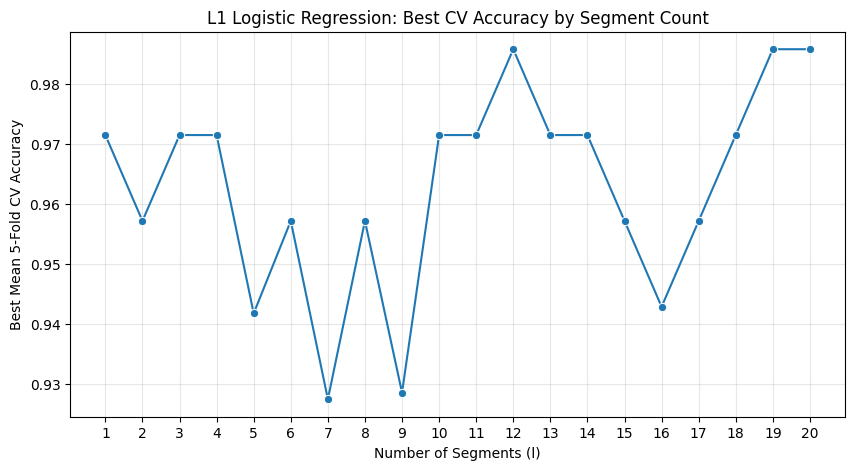

In [198]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=l1_cv_results,
    x="Segments",
    y="Mean CV Accuracy",
    marker="o",
)

plt.xticks(range(1, 21))
plt.xlabel("Number of Segments (l)")
plt.ylabel("Best Mean 5-Fold CV Accuracy")
plt.title(
    "L1 Logistic Regression: Best CV Accuracy by Segment Count"
)
plt.grid(alpha=0.3)

plt.show()

In [199]:
best_l1_test_features, best_l1_test_target = (
    build_segmented_dataset(
        ordered_instances,
        best_l1_number_of_segments,
        "Test",
    )
)

l1_test_predictions = best_l1_pipeline.predict(
    best_l1_test_features
)

l1_test_probabilities = (
    best_l1_pipeline.predict_proba(
        best_l1_test_features
    )[:, 1]
)

l1_test_accuracy = accuracy_score(
    best_l1_test_target,
    l1_test_predictions,
)

l1_test_auc = roc_auc_score(
    best_l1_test_target,
    l1_test_probabilities,
)

l1_test_confusion_matrix = confusion_matrix(
    best_l1_test_target,
    l1_test_predictions,
    labels=[0, 1],
)

print(
    "L1 test accuracy:",
    f"{l1_test_accuracy:.4f}",
)

print(
    "L1 test AUC:",
    f"{l1_test_auc:.4f}",
)

print(
    "L1 test confusion matrix:"
)

print(l1_test_confusion_matrix)

L1 test accuracy: 0.9474
L1 test AUC: 1.0000
L1 test confusion matrix:
[[15  0]
 [ 1  3]]


**Answer:** L1-penalized logistic regression was evaluated for \(l=1,\ldots,20\). For each value of \(l\), the inverse regularization strength \(C\) was selected using stratified five-fold cross-validation. Standardization was performed inside the cross-validation pipeline to prevent data leakage.

The selected model used

\[
l=12,\qquad C=0.464159,
\]

corresponding to an approximate reciprocal regularization strength of

\[
\frac{1}{C}=2.154435.
\]

The model achieved a mean five-fold cross-validation accuracy of 0.9857 with a standard deviation of 0.0286. Of the original

\[
6\times12\times7=504
\]

candidate features, the L1 penalty retained 5 features with nonzero coefficients.

When evaluated on the untouched test set, the selected L1 model achieved an accuracy of 0.9474 and an AUC of 1.0000. Its test confusion matrix was

\[
\begin{bmatrix}
15 & 0\\
1 & 3
\end{bmatrix}.
\]

Thus, L1 regularization produced a sparse model while maintaining strong classification performance. Neither the test set nor its labels were used to select \(l\) or \(C\).

#### 2(b)(ii) - Comparison with Variable Selection

In [200]:
binary_model_comparison = pd.DataFrame({
    "Method": [
        "RFE / Backward Selection",
        "L1-Penalized Logistic Regression",
    ],
    "Selected Segments (l)": [
        best_number_of_segments,
        best_l1_number_of_segments,
    ],
    "Selected Features": [
        best_number_of_features,
        best_l1_nonzero_count,
    ],
    "Mean CV Accuracy": [
        best_cv_accuracy,
        best_l1_cv_accuracy,
    ],
    "Test Accuracy": [
        test_accuracy,
        l1_test_accuracy,
    ],
    "Test AUC": [
        roc_auc_score(
            best_test_target,
            test_probabilities,
        ),
        l1_test_auc,
    ],
})

binary_model_comparison

,Method,Selected Segments (l),Selected Features,Mean CV Accuracy,Test Accuracy,Test AUC
0,RFE / Backward Selection,6,12,1.000000,0.947368,1.0
1,L1-Penalized Logistic Regression,12,5,0.985714,0.947368,1.0


**Answer:** The RFE variable-selection model achieved a higher mean five-fold cross-validation accuracy than the L1-penalized model:

\[
1.0000 \text{ versus } 0.9857.
\]

However, both models achieved exactly the same performance on the untouched test set. Each had a test accuracy of 0.9474, a test AUC of 1.0000, and the confusion matrix

\[
\begin{bmatrix}
15 & 0\\
1 & 3
\end{bmatrix}.
\]

Therefore, the RFE model performed slightly better according to the cross-validation estimate, but neither method performed better on the test set. The perfect RFE cross-validation accuracy should also be interpreted cautiously because the training dataset is small and the classes are completely separated.

The L1 model produced the sparser result. It retained only 5 nonzero coefficients, compared with 12 features retained by RFE, while achieving the same test accuracy and AUC.

L1-penalized logistic regression was easier to implement. Feature selection and coefficient estimation occurred simultaneously, and only \(l\) and \(C\) needed to be selected through cross-validation. In contrast, backward selection requires repeatedly fitting models, removing variables, and ensuring that selection occurs inside each cross-validation fold.

The assignment allowed RFE as an alternative to direct p-value pruning, and RFE was used in part 2(a). Direct p-value selection would have been especially problematic for these data because complete separation prevented the unpenalized logistic-regression coefficients and p-values from being reliably estimated.

Overall, L1 regularization is preferable for implementation simplicity and sparsity, while the RFE model had a slightly higher cross-validation accuracy. Their observed test performance was identical.

### 2(c) - Multiclass Classification

#### 2(c)(i) - L1-Penalized Multinomial Logistic Regression

The response variable now contains all seven activity classes. For each number of segments \(l\), an L1-penalized multinomial logistic-regression model is fitted. Both \(l\) and the inverse regularization strength \(C\) are selected using stratified cross-validation.

In [201]:
def build_multiclass_segmented_dataset(
    manifest,
    number_of_segments,
    split,
):
    selected_instances = manifest.loc[
        manifest["Split"].eq(split)
    ].sort_values(
        ["Activity", "Dataset"]
    )

    feature_records = []
    target_values = []

    for _, row in selected_instances.iterrows():
        instance_features = extract_segmented_features(
            row["Path"],
            number_of_segments,
        )

        feature_records.append(instance_features)
        target_values.append(row["Activity"])

    feature_matrix = pd.DataFrame(
        feature_records
    )

    target = pd.Series(
        target_values,
        name="Activity",
    )

    return feature_matrix, target

In [202]:
multiclass_example_features, multiclass_example_target = (
    build_multiclass_segmented_dataset(
        ordered_instances,
        1,
        "Train",
    )
)

multiclass_example_target.value_counts().sort_index()

Activity
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64

In [203]:
multiclass_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42,
)

Four-fold stratified cross-validation was used for the multiclass problem because the smallest training class, `bending2`, contains only four instances. 

Five-fold stratification could not place at least one `bending2` instance in every validation fold. Four folds are therefore the largest number that preserves all seven classes in every fold.

In [204]:
multiclass_candidate_c_values = np.logspace(
    -4,
    4,
    17,
)

multiclass_l1_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler(),
    ),
    (
        "logistic_regression",
        LogisticRegression(
            penalty="l1",
            solver="saga",
            max_iter=10000,
            tol=1e-3,
            random_state=42,
        ),
    ),
])

In [205]:
multiclass_result_records = []
multiclass_models_by_segment_count = {}

for number_of_segments in range(1, 21):
    (
        multiclass_training_features,
        multiclass_training_target,
    ) = build_multiclass_segmented_dataset(
        ordered_instances,
        number_of_segments,
        "Train",
    )

    multiclass_grid_search = GridSearchCV(
        estimator=multiclass_l1_pipeline,
        param_grid={
            "logistic_regression__C": (
                multiclass_candidate_c_values
            ),
        },
        scoring="accuracy",
        cv=multiclass_cv,
        n_jobs=-1,
        error_score="raise",
    )

    multiclass_grid_search.fit(
        multiclass_training_features,
        multiclass_training_target,
    )

    mean_scores = (
        multiclass_grid_search
        .cv_results_["mean_test_score"]
    )

    best_mean_score = mean_scores.max()

    tied_indices = np.flatnonzero(
        np.isclose(
            mean_scores,
            best_mean_score,
        )
    )

    candidate_values = np.asarray(
        multiclass_grid_search.cv_results_[
            "param_logistic_regression__C"
        ],
        dtype=float,
    )

    # Prefer stronger regularization among tied scores.
    selected_index = tied_indices[
        np.argmin(
            candidate_values[tied_indices]
        )
    ]

    selected_c = float(
        candidate_values[selected_index]
    )

    selected_score_sd = float(
        multiclass_grid_search.cv_results_[
            "std_test_score"
        ][selected_index]
    )

    selected_multiclass_pipeline = Pipeline([
        (
            "scaler",
            StandardScaler(),
        ),
        (
            "logistic_regression",
            LogisticRegression(
                penalty="l1",
                solver="saga",
                C=selected_c,
                max_iter=20000,
                tol=1e-4,
                random_state=42,
            ),
        ),
    ])

    selected_multiclass_pipeline.fit(
        multiclass_training_features,
        multiclass_training_target,
    )

    number_of_nonzero_coefficients = int(
        np.count_nonzero(
            selected_multiclass_pipeline
            .named_steps["logistic_regression"]
            .coef_
        )
    )

    multiclass_result_records.append({
        "Segments": number_of_segments,
        "C": selected_c,
        "Mean CV Accuracy": best_mean_score,
        "CV Accuracy SD": selected_score_sd,
        "Nonzero Coefficients": (
            number_of_nonzero_coefficients
        ),
    })

    multiclass_models_by_segment_count[
        number_of_segments
    ] = selected_multiclass_pipeline

    print(
        f"l={number_of_segments:2d}, "
        f"C={selected_c:.6f}, "
        f"accuracy={best_mean_score:.4f}, "
        f"nonzero="
        f"{number_of_nonzero_coefficients}"
    )

l= 1, C=1.000000, accuracy=0.9142, nonzero=25
l= 2, C=316.227766, accuracy=0.9273, nonzero=503
l= 3, C=100.000000, accuracy=0.8840, nonzero=505
l= 4, C=31.622777, accuracy=0.8840, nonzero=313
l= 5, C=31.622777, accuracy=0.8987, nonzero=390
l= 6, C=31.622777, accuracy=0.8987, nonzero=442
l= 7, C=100.000000, accuracy=0.8840, nonzero=1145
l= 8, C=31.622777, accuracy=0.8260, nonzero=645
l= 9, C=1.000000, accuracy=0.8701, nonzero=74
l=10, C=3.162278, accuracy=0.8260, nonzero=150
l=11, C=100.000000, accuracy=0.8554, nonzero=1769
l=12, C=31.622777, accuracy=0.8554, nonzero=785
l=13, C=0.316228, accuracy=0.8276, nonzero=58
l=14, C=100.000000, accuracy=0.8260, nonzero=2218
l=15, C=1.000000, accuracy=0.8546, nonzero=110
l=16, C=31.622777, accuracy=0.7966, nonzero=1024
l=17, C=0.316228, accuracy=0.8554, nonzero=61
l=18, C=0.316228, accuracy=0.8407, nonzero=60
l=19, C=0.316228, accuracy=0.8113, nonzero=64
l=20, C=0.316228, accuracy=0.8554, nonzero=70


In [206]:
multiclass_cv_results = pd.DataFrame(
    multiclass_result_records
)

ranked_multiclass_results = (
    multiclass_cv_results.sort_values(
        by=[
            "Mean CV Accuracy",
            "Nonzero Coefficients",
            "Segments",
            "C",
        ],
        ascending=[
            False,
            True,
            True,
            True,
        ],
    )
    .reset_index(drop=True)
)

ranked_multiclass_results

,Segments,C,Mean CV Accuracy,CV Accuracy SD,Nonzero Coefficients
0,2,316.227766,0.927288,0.025977,503
1,1,1.000000,0.914216,0.062536,25
2,5,31.622777,0.898693,0.024673,390
3,6,31.622777,0.898693,0.024673,442
4,4,31.622777,0.883987,0.041691,313
5,3,100.000000,0.883987,0.041691,505
6,7,100.000000,0.883987,0.002830,1145
7,9,1.000000,0.870098,0.075106,74
8,17,0.316228,0.855392,0.064801,61
9,20,0.316228,0.855392,0.049689,70


In [207]:
best_multiclass_result = (
    ranked_multiclass_results.iloc[0]
)

best_multiclass_number_of_segments = int(
    best_multiclass_result["Segments"]
)

best_multiclass_c = float(
    best_multiclass_result["C"]
)

best_multiclass_cv_accuracy = float(
    best_multiclass_result[
        "Mean CV Accuracy"
    ]
)

print(
    "Best number of segments:",
    best_multiclass_number_of_segments,
)

print(
    "Best C:",
    f"{best_multiclass_c:.6f}",
)

print(
    "Best mean CV accuracy:",
    f"{best_multiclass_cv_accuracy:.4f}",
)

Best number of segments: 2
Best C: 316.227766
Best mean CV accuracy: 0.9273


In [209]:
best_multiclass_pipeline = (
    multiclass_models_by_segment_count[
        best_multiclass_number_of_segments
    ]
)

(
    best_multiclass_training_features,
    best_multiclass_training_target,
) = build_multiclass_segmented_dataset(
    ordered_instances,
    best_multiclass_number_of_segments,
    "Train",
)

In [210]:
(
    best_multiclass_test_features,
    best_multiclass_test_target,
) = build_multiclass_segmented_dataset(
    ordered_instances,
    best_multiclass_number_of_segments,
    "Test",
)

multiclass_test_predictions = (
    best_multiclass_pipeline.predict(
        best_multiclass_test_features
    )
)

multiclass_test_probabilities = (
    best_multiclass_pipeline.predict_proba(
        best_multiclass_test_features
    )
)

multiclass_test_accuracy = accuracy_score(
    best_multiclass_test_target,
    multiclass_test_predictions,
)

multiclass_test_error = (
    1 - multiclass_test_accuracy
)

print(
    "Multiclass test accuracy:",
    f"{multiclass_test_accuracy:.4f}",
)

print(
    "Multiclass test error:",
    f"{multiclass_test_error:.4f}",
)

Multiclass test accuracy: 0.8421
Multiclass test error: 0.1579


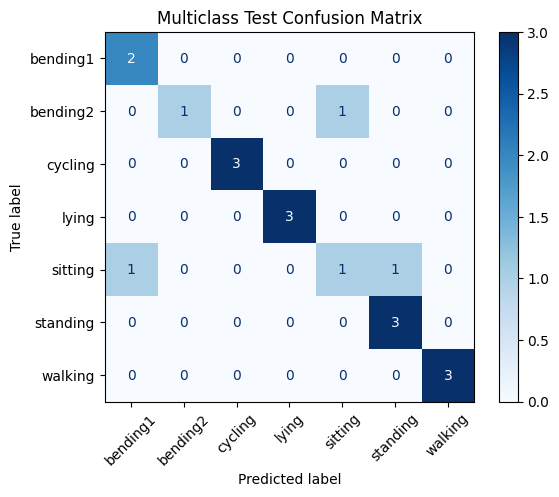

In [211]:
multiclass_classes = (
    best_multiclass_pipeline
    .named_steps["logistic_regression"]
    .classes_
)

multiclass_test_confusion_matrix = (
    confusion_matrix(
        best_multiclass_test_target,
        multiclass_test_predictions,
        labels=multiclass_classes,
    )
)

multiclass_confusion_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=(
            multiclass_test_confusion_matrix
        ),
        display_labels=multiclass_classes,
    )
)

multiclass_confusion_display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
)

plt.title(
    "Multiclass Test Confusion Matrix"
)
plt.show()

In [212]:
from sklearn.metrics import auc
from sklearn.preprocessing import label_binarize

binarized_multiclass_test_target = (
    label_binarize(
        best_multiclass_test_target,
        classes=multiclass_classes,
    )
)

multiclass_roc_results = {}

for class_index, class_name in enumerate(
    multiclass_classes
):
    class_false_positive_rate, class_true_positive_rate, _ = (
        roc_curve(
            binarized_multiclass_test_target[
                :,
                class_index,
            ],
            multiclass_test_probabilities[
                :,
                class_index,
            ],
        )
    )

    class_auc = auc(
        class_false_positive_rate,
        class_true_positive_rate,
    )

    multiclass_roc_results[class_name] = {
        "False Positive Rate": (
            class_false_positive_rate
        ),
        "True Positive Rate": (
            class_true_positive_rate
        ),
        "AUC": class_auc,
    }

In [213]:
multiclass_auc_table = pd.DataFrame({
    "Class": multiclass_classes,
    "One-vs-Rest AUC": [
        multiclass_roc_results[
            class_name
        ]["AUC"]
        for class_name in multiclass_classes
    ],
})

multiclass_auc_table

,Class,One-vs-Rest AUC
0,bending1,1.000000
1,bending2,0.794118
2,cycling,1.000000
3,lying,1.000000
4,sitting,0.895833
5,standing,1.000000
6,walking,1.000000


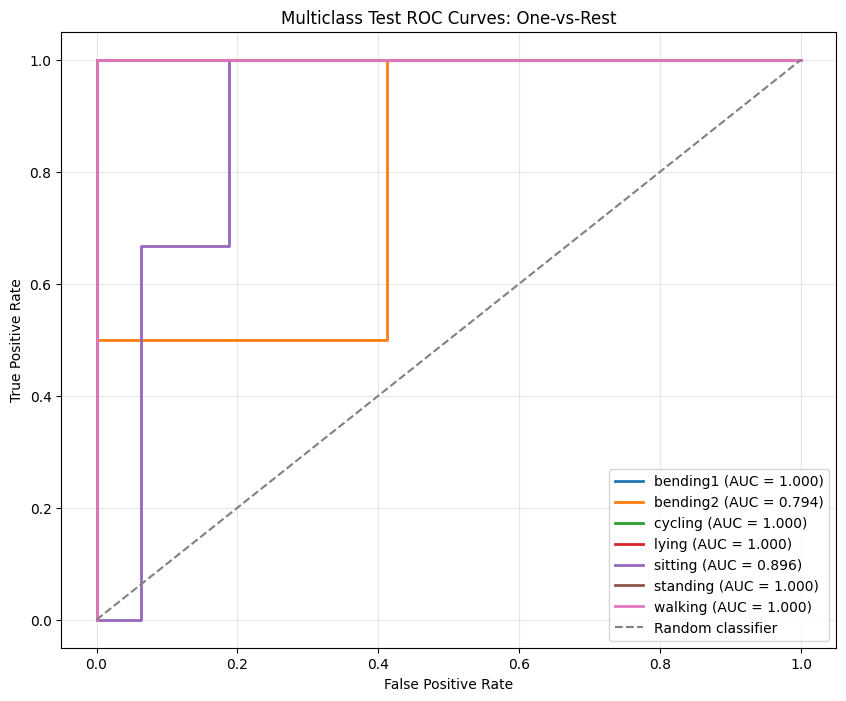

In [214]:
plt.figure(figsize=(10, 8))

for class_name in multiclass_classes:
    class_results = (
        multiclass_roc_results[class_name]
    )

    plt.plot(
        class_results["False Positive Rate"],
        class_results["True Positive Rate"],
        linewidth=2,
        label=(
            f"{class_name} "
            f"(AUC = "
            f"{class_results['AUC']:.3f})"
        ),
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier",
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    "Multiclass Test ROC Curves: One-vs-Rest"
)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

In [215]:
multiclass_macro_auc = roc_auc_score(
    binarized_multiclass_test_target,
    multiclass_test_probabilities,
    average="macro",
    multi_class="ovr",
)

multiclass_weighted_auc = roc_auc_score(
    binarized_multiclass_test_target,
    multiclass_test_probabilities,
    average="weighted",
    multi_class="ovr",
)

multiclass_micro_auc = roc_auc_score(
    binarized_multiclass_test_target,
    multiclass_test_probabilities,
    average="micro",
    multi_class="ovr",
)

print(
    "Macro-average AUC:",
    f"{multiclass_macro_auc:.4f}",
)

print(
    "Weighted-average AUC:",
    f"{multiclass_weighted_auc:.4f}",
)

print(
    "Micro-average AUC:",
    f"{multiclass_micro_auc:.4f}",
)

Macro-average AUC: 0.9557
Weighted-average AUC: 0.9619
Micro-average AUC: 0.9718


**Answer:** L1-penalized multinomial logistic regression was used to classify all seven activities. Four-fold stratified cross-validation was used because the smallest training class, `bending2`, contains only four instances, making fully stratified five-fold cross-validation impossible.

Cross-validation selected

\[
l=2,\qquad C=316.227766,
\]

with a mean validation accuracy of approximately 0.9273. The large value of  (C\) indicates that the selected model used a relatively weak L1 penalty.

On the untouched test set, the classifier correctly classified 16 of the 19 instances. Its test accuracy was therefore

\[
\frac{16}{19}=0.8421,
\]

and its test error was

\[
1-0.8421=\frac{3}{19}=0.1579.
\]

The confusion matrix showed three errors: one `bending2` instance was classified as `sitting`, and two `sitting` instances were classified as `bending1` and `standing`. All instances of `bending1`, `cycling`, `lying`, `standing`, and `walking` were classified correctly.

For multiclass ROC analysis, each activity was treated as the positive class while the remaining six activities were treated as the negative class. This one-vs-rest procedure produced a separate ROC curve and AUC for each activity. 

The macro-average, weighted-average, and micro-average test AUC values were approximately 0.9557, 0.9619, and 0.9718, respectively. The weakest class-specific performance occurred for `bending2` and `sitting`, which is consistent with the off-diagonal errors in the confusion matrix.

#### 2(c)(ii) - Gaussian and Multinomial Naive Bayes

In [216]:
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB

naive_bayes_result_records = []

for number_of_segments in range(1, 21):
    (
        naive_bayes_training_features,
        naive_bayes_training_target,
    ) = build_multiclass_segmented_dataset(
        ordered_instances,
        number_of_segments,
        "Train",
    )

    naive_bayes_models = {
        "Gaussian Naive Bayes": GaussianNB(),
        "Multinomial Naive Bayes": MultinomialNB(),
    }

    for model_name, model in naive_bayes_models.items():
        cv_scores = cross_val_score(
            estimator=model,
            X=naive_bayes_training_features,
            y=naive_bayes_training_target,
            scoring="accuracy",
            cv=multiclass_cv,
            n_jobs=-1,
            error_score="raise",
        )

        naive_bayes_result_records.append({
            "Model": model_name,
            "Segments": number_of_segments,
            "Mean CV Accuracy": cv_scores.mean(),
            "CV Accuracy SD": cv_scores.std(),
        })

naive_bayes_cv_results = pd.DataFrame(
    naive_bayes_result_records
)

In [217]:
naive_bayes_cv_results.sort_values(
    by=[
        "Model",
        "Mean CV Accuracy",
        "Segments",
    ],
    ascending=[
        True,
        False,
        True,
    ],
)

,Model,Segments,Mean CV Accuracy,CV Accuracy SD
0,Gaussian Naive Bayes,1,0.841503,0.102863
2,Gaussian Naive Bayes,2,0.825980,0.110131
4,Gaussian Naive Bayes,3,0.697712,0.103794
6,Gaussian Naive Bayes,4,0.695261,0.065416
10,Gaussian Naive Bayes,6,0.651961,0.072542
14,Gaussian Naive Bayes,8,0.638072,0.015566
8,Gaussian Naive Bayes,5,0.637255,0.029412
12,Gaussian Naive Bayes,7,0.624183,0.082221
18,Gaussian Naive Bayes,10,0.622549,0.068452
20,Gaussian Naive Bayes,11,0.607843,0.079647


In [218]:
best_naive_bayes_results = (
    naive_bayes_cv_results.sort_values(
        by=[
            "Model",
            "Mean CV Accuracy",
            "Segments",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .groupby(
        "Model",
        as_index=False,
    )
    .first()
)

best_naive_bayes_results

,Model,Segments,Mean CV Accuracy,CV Accuracy SD
0,Gaussian Naive Bayes,1,0.841503,0.102863
1,Multinomial Naive Bayes,1,0.870915,0.058892


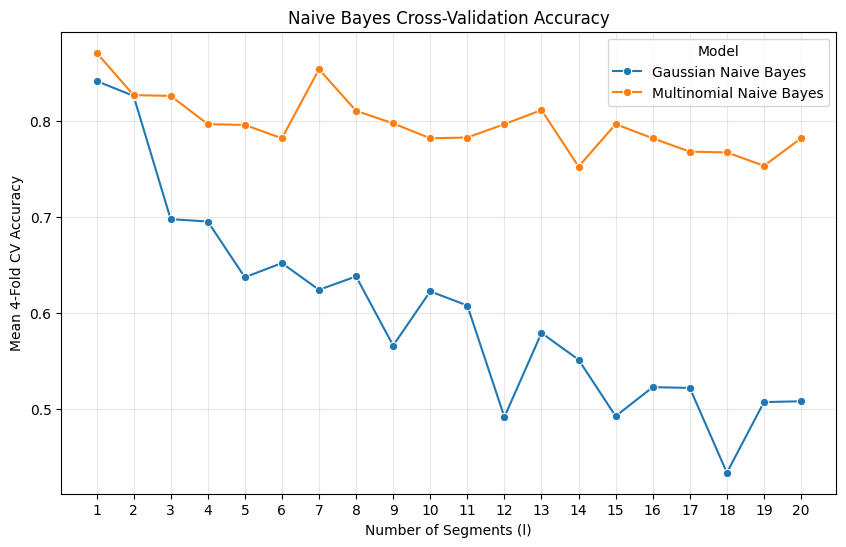

In [219]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=naive_bayes_cv_results,
    x="Segments",
    y="Mean CV Accuracy",
    hue="Model",
    marker="o",
)

plt.xticks(range(1, 21))
plt.xlabel("Number of Segments (l)")
plt.ylabel("Mean 4-Fold CV Accuracy")
plt.title(
    "Naive Bayes Cross-Validation Accuracy"
)
plt.grid(alpha=0.3)
plt.show()

In [220]:
best_gaussian_l = int(
    best_naive_bayes_results.loc[
        best_naive_bayes_results["Model"].eq(
            "Gaussian Naive Bayes"
        ),
        "Segments",
    ].iloc[0]
)

(
    gaussian_training_features,
    gaussian_training_target,
) = build_multiclass_segmented_dataset(
    ordered_instances,
    best_gaussian_l,
    "Train",
)

(
    gaussian_test_features,
    gaussian_test_target,
) = build_multiclass_segmented_dataset(
    ordered_instances,
    best_gaussian_l,
    "Test",
)

In [221]:
gaussian_nb_model = GaussianNB()

gaussian_nb_model.fit(
    gaussian_training_features,
    gaussian_training_target,
)

gaussian_test_predictions = (
    gaussian_nb_model.predict(
        gaussian_test_features
    )
)

gaussian_test_probabilities = (
    gaussian_nb_model.predict_proba(
        gaussian_test_features
    )
)

gaussian_test_accuracy = accuracy_score(
    gaussian_test_target,
    gaussian_test_predictions,
)

gaussian_test_error = (
    1 - gaussian_test_accuracy
)

print(
    "Gaussian NB test accuracy:",
    f"{gaussian_test_accuracy:.4f}",
)

print(
    "Gaussian NB test error:",
    f"{gaussian_test_error:.4f}",
)

Gaussian NB test accuracy: 0.8947
Gaussian NB test error: 0.1053


In [222]:
best_multinomial_l = int(
    best_naive_bayes_results.loc[
        best_naive_bayes_results["Model"].eq(
            "Multinomial Naive Bayes"
        ),
        "Segments",
    ].iloc[0]
)

(
    multinomial_training_features,
    multinomial_training_target,
) = build_multiclass_segmented_dataset(
    ordered_instances,
    best_multinomial_l,
    "Train",
)

(
    multinomial_test_features,
    multinomial_test_target,
) = build_multiclass_segmented_dataset(
    ordered_instances,
    best_multinomial_l,
    "Test",
)

In [223]:
print(
    "Minimum training feature:",
    multinomial_training_features
    .to_numpy()
    .min(),
)

print(
    "Minimum test feature:",
    multinomial_test_features
    .to_numpy()
    .min(),
)

assert (
    multinomial_training_features
    .to_numpy()
    .min()
    >= 0
)

assert (
    multinomial_test_features
    .to_numpy()
    .min()
    >= 0
)

Minimum training feature: 0.0
Minimum test feature: 0.0


In [224]:
multinomial_nb_model = MultinomialNB()

multinomial_nb_model.fit(
    multinomial_training_features,
    multinomial_training_target,
)

multinomial_test_predictions = (
    multinomial_nb_model.predict(
        multinomial_test_features
    )
)

multinomial_test_probabilities = (
    multinomial_nb_model.predict_proba(
        multinomial_test_features
    )
)

multinomial_test_accuracy = accuracy_score(
    multinomial_test_target,
    multinomial_test_predictions,
)

multinomial_test_error = (
    1 - multinomial_test_accuracy
)

print(
    "Multinomial NB test accuracy:",
    f"{multinomial_test_accuracy:.4f}",
)

print(
    "Multinomial NB test error:",
    f"{multinomial_test_error:.4f}",
)

Multinomial NB test accuracy: 0.8947
Multinomial NB test error: 0.1053


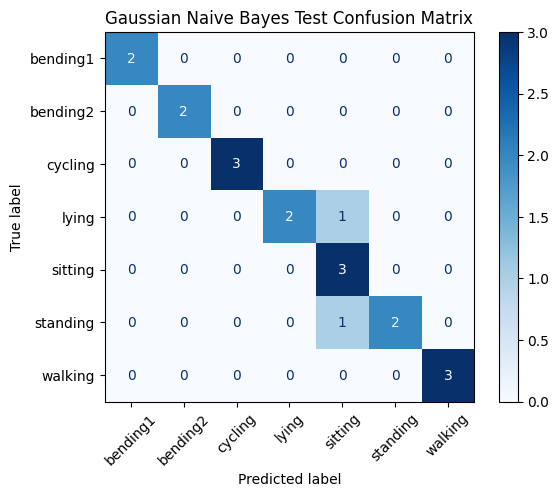

In [225]:
naive_bayes_classes = (
    gaussian_nb_model.classes_
)

gaussian_test_confusion_matrix = confusion_matrix(
    gaussian_test_target,
    gaussian_test_predictions,
    labels=naive_bayes_classes,
)

gaussian_confusion_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=(
            gaussian_test_confusion_matrix
        ),
        display_labels=naive_bayes_classes,
    )
)

gaussian_confusion_display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
)

plt.title(
    "Gaussian Naive Bayes Test Confusion Matrix"
)
plt.show()

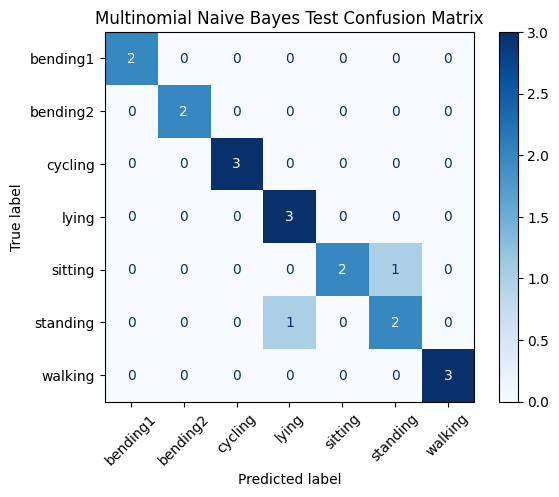

In [226]:
multinomial_test_confusion_matrix = (
    confusion_matrix(
        multinomial_test_target,
        multinomial_test_predictions,
        labels=naive_bayes_classes,
    )
)

multinomial_confusion_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=(
            multinomial_test_confusion_matrix
        ),
        display_labels=naive_bayes_classes,
    )
)

multinomial_confusion_display.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
)

plt.title(
    "Multinomial Naive Bayes Test Confusion Matrix"
)
plt.show()

In [227]:
def calculate_multiclass_auc(
    true_target,
    predicted_probabilities,
    classes,
):
    binarized_target = label_binarize(
        true_target,
        classes=classes,
    )

    per_class_results = []

    for class_index, class_name in enumerate(
        classes
    ):
        class_auc = roc_auc_score(
            binarized_target[:, class_index],
            predicted_probabilities[
                :,
                class_index,
            ],
        )

        per_class_results.append({
            "Class": class_name,
            "AUC": class_auc,
        })

    macro_auc = roc_auc_score(
        binarized_target,
        predicted_probabilities,
        average="macro",
        multi_class="ovr",
    )

    weighted_auc = roc_auc_score(
        binarized_target,
        predicted_probabilities,
        average="weighted",
        multi_class="ovr",
    )

    micro_auc = roc_auc_score(
        binarized_target,
        predicted_probabilities,
        average="micro",
        multi_class="ovr",
    )

    return (
        pd.DataFrame(per_class_results),
        macro_auc,
        weighted_auc,
        micro_auc,
    )

In [228]:
(
    gaussian_auc_by_class,
    gaussian_macro_auc,
    gaussian_weighted_auc,
    gaussian_micro_auc,
) = calculate_multiclass_auc(
    gaussian_test_target,
    gaussian_test_probabilities,
    naive_bayes_classes,
)

gaussian_auc_by_class

,Class,AUC
0,bending1,1.000000
1,bending2,1.000000
2,cycling,1.000000
3,lying,0.802083
4,sitting,0.947917
5,standing,1.000000
6,walking,1.000000


In [229]:
(
    multinomial_auc_by_class,
    multinomial_macro_auc,
    multinomial_weighted_auc,
    multinomial_micro_auc,
) = calculate_multiclass_auc(
    multinomial_test_target,
    multinomial_test_probabilities,
    naive_bayes_classes,
)

multinomial_auc_by_class

,Class,AUC
0,bending1,1.000000
1,bending2,1.000000
2,cycling,1.000000
3,lying,1.000000
4,sitting,0.958333
5,standing,0.937500
6,walking,1.000000


In [230]:
naive_bayes_auc_summary = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes",
    ],
    "Macro AUC": [
        gaussian_macro_auc,
        multinomial_macro_auc,
    ],
    "Weighted AUC": [
        gaussian_weighted_auc,
        multinomial_weighted_auc,
    ],
    "Micro AUC": [
        gaussian_micro_auc,
        multinomial_micro_auc,
    ],
})

naive_bayes_auc_summary

,Model,Macro AUC,Weighted AUC,Micro AUC
0,Gaussian Naive Bayes,0.964286,0.960526,0.959603
1,Multinomial Naive Bayes,0.985119,0.983553,0.992613


In [231]:
def plot_multiclass_roc(
    true_target,
    predicted_probabilities,
    classes,
    title,
):
    binarized_target = label_binarize(
        true_target,
        classes=classes,
    )

    plt.figure(figsize=(10, 8))

    for class_index, class_name in enumerate(
        classes
    ):
        class_fpr, class_tpr, _ = roc_curve(
            binarized_target[:, class_index],
            predicted_probabilities[
                :,
                class_index,
            ],
        )

        class_auc = auc(
            class_fpr,
            class_tpr,
        )

        plt.plot(
            class_fpr,
            class_tpr,
            linewidth=2,
            label=(
                f"{class_name} "
                f"(AUC = {class_auc:.3f})"
            ),
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Random classifier",
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()

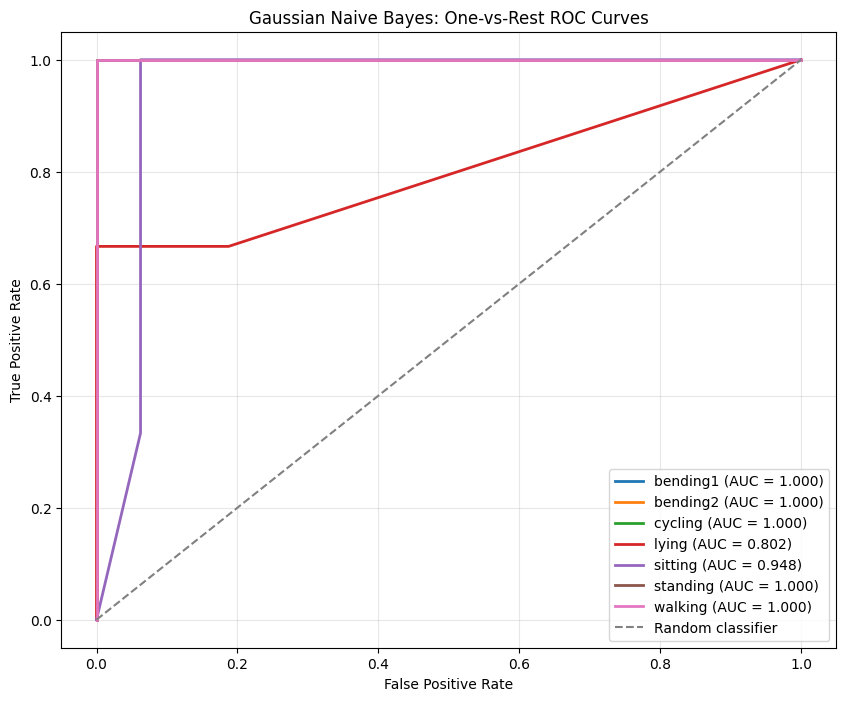

In [232]:
plot_multiclass_roc(
    gaussian_test_target,
    gaussian_test_probabilities,
    naive_bayes_classes,
    "Gaussian Naive Bayes: One-vs-Rest ROC Curves",
)

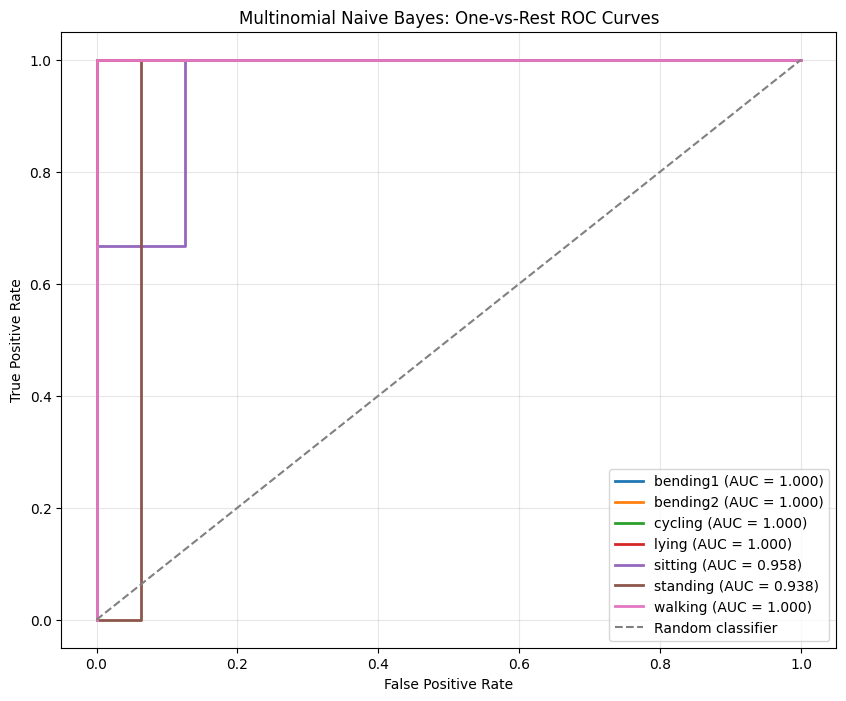

In [233]:
plot_multiclass_roc(
    multinomial_test_target,
    multinomial_test_probabilities,
    naive_bayes_classes,
    "Multinomial Naive Bayes: One-vs-Rest ROC Curves",
)

**Answer:** Gaussian and Multinomial Naive Bayes classifiers were evaluated for \(l=1,\ldots,20\) using four-fold stratified cross-validation. Both classifiers selected \(l=1\).

Gaussian Naive Bayes achieved a mean cross-validation accuracy of 0.8415 and a test accuracy of 0.8947, corresponding to a test error of

\[
1-0.8947=0.1053.
\]

It misclassified one `lying` instance and one `standing` instance as `sitting`. Its macro-average, weighted-average, and micro-average AUC values were approximately 0.9643, 0.9605, and 0.9596.

Multinomial Naive Bayes achieved a higher mean cross-validation accuracy of 0.8709. It also achieved a test accuracy of 0.8947 and a test error of

\[
0.1053.
\]

It misclassified one `sitting` instance as `standing` and one `standing` instance as `lying`. Its macro-average, weighted-average, and micro-average AUC values were approximately 0.9851, 0.9836, and 0.9926.

Thus, both Naive Bayes classifiers had the same test accuracy and test error. However, Multinomial Naive Bayes had higher cross-validation accuracy and higher multiclass AUC values. 

Among the two Naive Bayes methods, Multinomial Naive Bayes performed better overall.

#### 2(c)(iii) - Multiclass Model Comparison

In [234]:
multiclass_model_comparison = pd.DataFrame({
    "Model": [
        "L1 Multinomial Logistic Regression",
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes",
    ],
    "Selected Segments": [
        best_multiclass_number_of_segments,
        best_gaussian_l,
        best_multinomial_l,
    ],
    "Mean CV Accuracy": [
        best_multiclass_cv_accuracy,
        best_naive_bayes_results.loc[
            best_naive_bayes_results["Model"].eq(
                "Gaussian Naive Bayes"
            ),
            "Mean CV Accuracy",
        ].iloc[0],
        best_naive_bayes_results.loc[
            best_naive_bayes_results["Model"].eq(
                "Multinomial Naive Bayes"
            ),
            "Mean CV Accuracy",
        ].iloc[0],
    ],
    "Test Accuracy": [
        multiclass_test_accuracy,
        gaussian_test_accuracy,
        multinomial_test_accuracy,
    ],
    "Test Error": [
        multiclass_test_error,
        gaussian_test_error,
        multinomial_test_error,
    ],
    "Macro AUC": [
        multiclass_macro_auc,
        gaussian_macro_auc,
        multinomial_macro_auc,
    ],
    "Micro AUC": [
        multiclass_micro_auc,
        gaussian_micro_auc,
        multinomial_micro_auc,
    ],
})

multiclass_model_comparison

,Model,Selected Segments,Mean CV Accuracy,Test Accuracy,Test Error,Macro AUC,Micro AUC
0,L1 Multinomial Logistic Regression,2,0.927288,0.842105,0.157895,0.955707,0.971837
1,Gaussian Naive Bayes,1,0.841503,0.894737,0.105263,0.964286,0.959603
2,Multinomial Naive Bayes,1,0.870915,0.894737,0.105263,0.985119,0.992613


**Answer:** Multinomial Naive Bayes performed best on the held-out test set for this problem. Gaussian and Multinomial Naive Bayes both achieved a test accuracy of 0.8947 and a test error of 0.1053, compared with a test accuracy of 0.8421 and test error of 0.1579 for L1-penalized multinomial logistic regression.

Between the two Naive Bayes classifiers, Multinomial Naive Bayes performed better overall. It had a higher cross-validation accuracy than Gaussian Naive Bayes, 0.8709 versus 0.8415, and substantially higher macro and micro multiclass AUC values. Its macro AUC was 0.9851 and its micro AUC was 0.9926.

L1-penalized multinomial logistic regression had the highest cross-validation accuracy, 0.9273, but it made three errors on the test set instead of two. Therefore, the cross-validation and test rankings were not identical.

Based primarily on the held-out test error and supported by the multiclass AUC values, Multinomial Naive Bayes is the best of the three methods for this dataset. This conclusion should be interpreted cautiously because the test set contains only 19 instances, so one additional error changes test accuracy by approximately 5.26 percentage points.

## 3 - ISLR, 4.8.3

**Q.** This problem relates to the QDA model, in which the observations within each class are drawn from a normal distribution with a class- specific mean vector and a class specific covariance matrix. We con- sider the simple case where p = 1; i.e. there is only one feature.

Suppose that we have K classes, and that if an observation belongs to the kth class then X comes from a one-dimensional normal dis- tribution, X ∼ N (μk, σ2 k). Recall that the density function for the one-dimensional normal distribution is given in (4.16). Prove that in this case, the Bayes classifier is not linear. Argue that it is in fact quadratic.

Hint: For this problem, you should follow the arguments laid out in Section 4.4.1, but without making the assumption that σ2 1 = · · · = σ2 K.

**Answer:** Let \(\pi_k=P(Y=k)\) denote the prior probability that an observation belongs to class \(k\). For class \(k\), the conditional density of \(X\) is

\[
f_k(x)
=
\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(
-\frac{(x-\mu_k)^2}{2\sigma_k^2}
\right).
\]

Using Bayes' theorem,

\[
P(Y=k\mid X=x)
=
\frac{\pi_k f_k(x)}
{\sum_{j=1}^{K}\pi_j f_j(x)}.
\]

The denominator is the same for every class, so the Bayes classifier assigns \(x\) to the class that maximizes

\[
\pi_k f_k(x).
\]

Because the logarithm is strictly increasing, this is equivalent to maximizing

\[
\log\left(\pi_k f_k(x)\right).
\]

Substituting the normal density gives

\[
\log\left(\pi_k f_k(x)\right)
=
\log(\pi_k)
-\log(\sigma_k)
-\frac{1}{2}\log(2\pi)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
\]

The term \(-\frac{1}{2}\log(2\pi)\) is identical for all classes and can be removed. Therefore, the discriminant function for class \(k\) can be written as

\[
\delta_k(x)
=
\log(\pi_k)
-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
\]

Expanding the squared term,

\[
(x-\mu_k)^2
=
x^2-2\mu_kx+\mu_k^2,
\]

so

\[
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+
\frac{\mu_k}{\sigma_k^2}x
-
\frac{\mu_k^2}{2\sigma_k^2}
-
\log(\sigma_k)
+
\log(\pi_k).
\]

Thus, \(\delta_k(x)\) contains an \(x^2\) term whose coefficient is

\[
-\frac{1}{2\sigma_k^2}.
\]

Because the variance \(\sigma_k^2\) is allowed to differ between classes, this quadratic coefficient is class-specific.

To see the form of the decision boundary, consider two classes \(k\) and \(j\). Their boundary occurs where

\[
\delta_k(x)=\delta_j(x).
\]

Equivalently,

\[
\left(
\frac{1}{2\sigma_j^2}
-
\frac{1}{2\sigma_k^2}
\right)x^2
+
\left(
\frac{\mu_k}{\sigma_k^2}
-
\frac{\mu_j}{\sigma_j^2}
\right)x
+
\log\left(\frac{\pi_k}{\pi_j}\right)
-
\log\left(\frac{\sigma_k}{\sigma_j}\right)
-
\frac{\mu_k^2}{2\sigma_k^2}
+
\frac{\mu_j^2}{2\sigma_j^2}
=0.
\]

This is a quadratic equation in \(x\). When \(\sigma_k^2\neq\sigma_j^2\), the coefficient of \(x^2\) does not cancel, so the decision boundary is quadratic rather than linear.

If all classes had the same variance,

\[
\sigma_1^2=\cdots=\sigma_K^2,
\]

then the \(x^2\) terms would be identical for every class and would cancel when comparing discriminant functions. The resulting boundary would be linear, which is the LDA case. Since QDA allows each class to have a different variance, its discriminant functions and pairwise decision boundaries are quadratic in general.

## 4 ISLR 4.8.7

**Q** Suppose that we wish to predict whether a given stock will issue a dividend this year (“Yes” or “No”) based on X, last year’s percent profit. We examine a large number of companies and discover that the mean value of X for companies that issued a dividend was ¯X = 10, while the mean for those that didn’t was ¯X = 0. In addition, the variance of X for these two sets of companies was ˆσ2 = 36. Finally, 80 % of companies issued dividends. Assuming that X follows a nor- mal distribution, predict the probability that a company will issue a dividend this year given that its percentage profit was X = 4 last year.

Hint: Recall that the density function for a normal random variable is f (x) = 1√2πσ2 e−(x−μ)2/2σ2. You will need to use Bayes’ theorem.